# Overview {#sec-pca}




In [1]:
#| code-fold: true
#| code-summary: Code to prepare the environment

import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, LabelEncoder

curfolder = os.getcwd()

# This is where our features live
features = os.path.join(curfolder, 'Datasets')
df = pd.read_csv(os.path.join(features, 'sapiens_features_noconcept_noLP.csv'))

df.head()

,gross__magnitude__arm_speed_Gmean,gross__variability__arm_speed_Gstd,gross__magnitude__arm_speed_peak_mean,gross__variability__arm_speed_peak_std,gross__rhythm__arm_speed_peak_n,gross__rhythm__arm_speed_peak_rate,gross__rhythm__arm_speed_mod_depth,gross__magnitude__arm_acc_Gmean,gross__variability__arm_acc_Gstd,gross__magnitude__arm_acc_peak_mean,...,fine__coordination__corr_index_middle,fine__coordination__corr_middle_ring,fine__coordination__corr_ring_pinky,fine__proxdist__distal_proximal_ratio,fine__variability__flexion_entropy,fileID,group,groupID,concept,pcnID
0,0.552371,0.486426,1.377468,0.542730,4,0.851064,1.030222,2.064245,1.947847,4.349243,...,0.463926,0.726656,0.426655,0.975861,3.073719,GP01_ANSTECKEN,GP01,Gesture,ANSTECKEN,GP01
1,1.053819,0.653684,2.200471,0.711201,4,0.845070,1.443957,3.122254,2.348642,6.000079,...,0.978735,0.923227,0.760044,0.850163,2.952784,GP01_BODEN,GP01,Gesture,BODEN,GP01
2,0.954794,0.768327,2.031465,1.121333,4,0.851064,1.835851,3.638679,2.860333,5.610632,...,0.671586,0.818125,0.855292,1.019093,3.166920,GP01_BRIEF,GP01,Gesture,BRIEF,GP01
3,0.385791,0.478493,1.225327,0.688305,3,0.638298,1.045060,1.589367,1.799295,4.567698,...,0.919347,0.959597,0.856491,1.034595,2.484640,GP01_BUERO,GP01,Gesture,BUERO,GP01
4,0.475486,0.705323,2.406980,NaN,1,0.212766,NaN,1.934251,2.938965,3.545241,...,0.945602,0.957496,0.925923,0.908041,2.567418,GP01_ENTSCHULDIGEN,GP01,Gesture,ENTSCHULDIGEN,GP01


In [4]:
# Show me proportion of missing values for each column
missing_values = df.isnull().mean() * 100
missing_values = missing_values[missing_values > 0]
print("Proportion of missing values in each column:")
missing_values

Proportion of missing values in each column:


gross__variability__arm_speed_peak_std    2.060738
gross__rhythm__arm_speed_mod_depth        2.060738
gross__variability__arm_acc_peak_std      0.108460
gross__rhythm__arm_acc_mod_depth          0.108460
dtype: float64

In [5]:
# how many rows if the df have any missing value
rows_with_missing_values = df[df.isnull().any(axis=1)]
print(f"Number of rows with missing values: {len(rows_with_missing_values)}")

# frop rows with missing values
df = df.dropna()
print(f"Number of rows after dropping missing values: {len(df)}")

Number of rows with missing values: 20
Number of rows after dropping missing values: 902


In [6]:
# how many rows in total?
total_rows = len(df)
print(f"Total number of rows: {total_rows}")

Total number of rows: 902


In [7]:
# how many columns is there
total_columns = len(df.columns)
print(f"Total number of columns: {total_columns}")

Total number of columns: 60


In [8]:
sampled_df = df.copy()

# how many unique groupID are there?
unique_groupIDs = sampled_df['groupID'].nunique()
print(f"Number of unique groupIDs: {unique_groupIDs}")

# get rid of LP group
sampled_df = sampled_df[sampled_df['groupID'] != 'LP']

# show them
print("Unique groupIDs:")
print(sampled_df['groupID'].unique())

Number of unique groupIDs: 4
Unique groupIDs:
<StringArray>
['Gesture', 'Sign', 'Learner_1', 'Learner_2']
Length: 4, dtype: str


In [9]:
sampled_df.head(50)

,gross__magnitude__arm_speed_Gmean,gross__variability__arm_speed_Gstd,gross__magnitude__arm_speed_peak_mean,gross__variability__arm_speed_peak_std,gross__rhythm__arm_speed_peak_n,gross__rhythm__arm_speed_peak_rate,gross__rhythm__arm_speed_mod_depth,gross__magnitude__arm_acc_Gmean,gross__variability__arm_acc_Gstd,gross__magnitude__arm_acc_peak_mean,...,fine__coordination__corr_index_middle,fine__coordination__corr_middle_ring,fine__coordination__corr_ring_pinky,fine__proxdist__distal_proximal_ratio,fine__variability__flexion_entropy,fileID,group,groupID,concept,pcnID
0,0.552371,0.486426,1.377468,0.542730,4,0.851064,1.030222,2.064245,1.947847,4.349243,...,0.463926,0.726656,0.426655,0.975861,3.073719,GP01_ANSTECKEN,GP01,Gesture,ANSTECKEN,GP01
1,1.053819,0.653684,2.200471,0.711201,4,0.845070,1.443957,3.122254,2.348642,6.000079,...,0.978735,0.923227,0.760044,0.850163,2.952784,GP01_BODEN,GP01,Gesture,BODEN,GP01
2,0.954794,0.768327,2.031465,1.121333,4,0.851064,1.835851,3.638679,2.860333,5.610632,...,0.671586,0.818125,0.855292,1.019093,3.166920,GP01_BRIEF,GP01,Gesture,BRIEF,GP01
3,0.385791,0.478493,1.225327,0.688305,3,0.638298,1.045060,1.589367,1.799295,4.567698,...,0.919347,0.959597,0.856491,1.034595,2.484640,GP01_BUERO,GP01,Gesture,BUERO,GP01
5,1.212209,0.936830,2.552069,0.800775,4,0.851064,2.255823,5.144732,3.626501,9.469993,...,0.817118,0.908838,0.865670,0.531514,2.798595,GP01_GIRAFFE,GP01,Gesture,GIRAFFE,GP01
6,0.934655,1.223187,3.778077,0.280621,2,0.425532,3.634399,3.988631,4.406260,11.715147,...,0.953764,0.984255,0.955592,0.544597,2.454548,GP01_GOTT,GP01,Gesture,GOTT,GP01
7,0.996011,0.991806,2.998488,0.691998,3,0.638298,2.488136,3.750782,3.669915,8.566859,...,0.838591,0.958472,0.918495,0.821017,2.701999,GP01_HEMD,GP01,Gesture,HEMD,GP01
8,0.678410,0.565396,1.332935,0.610117,5,1.063830,1.112777,2.443043,1.835314,4.073219,...,0.231439,0.890699,0.907721,0.532327,2.900614,GP01_SCHOKOLADE,GP01,Gesture,SCHOKOLADE,GP01
9,1.381503,0.704452,2.251771,0.460238,7,1.489362,1.552995,4.676557,2.103714,6.910719,...,0.814066,0.941512,0.972875,0.479747,3.011300,GP01_STAUBSAUGEN,GP01,Gesture,STAUBSAUGEN,GP01
10,0.738641,0.790776,1.719448,1.234414,4,0.845070,1.585408,2.981175,2.760191,6.172898,...,0.983269,0.995475,0.975647,0.759590,2.555083,GP01_WENIG,GP01,Gesture,WENIG,GP01


In [10]:
#| code-fold: true
#| code-summary: Custom functions

# Function to clean the data
def clean_df(df):

    # Fill NaNs with 0
    df = df.fillna(0)   # FLAGGED: this we might change, maybe not the best method (alternative: MICE)

    # Save values from groupID
    groupID = df['groupID']
    concepts = df['concept']

    # Leave only numerical cols, except groupID
    df = df.select_dtypes(include=['float64','int64'])

    # Add back correction_info
    df['groupID'] = groupID
    df['concept'] = concepts
    
    return df

In [11]:
# Clean the df
df_clean = clean_df(sampled_df)

df_clean.head(15)

,gross__magnitude__arm_speed_Gmean,gross__variability__arm_speed_Gstd,gross__magnitude__arm_speed_peak_mean,gross__variability__arm_speed_peak_std,gross__rhythm__arm_speed_peak_n,gross__rhythm__arm_speed_peak_rate,gross__rhythm__arm_speed_mod_depth,gross__magnitude__arm_acc_Gmean,gross__variability__arm_acc_Gstd,gross__magnitude__arm_acc_peak_mean,...,fine__variability__flexion_speed_std,fine__smoothness__flexion_jerk,fine__coordination__finger_independence,fine__coordination__corr_index_middle,fine__coordination__corr_middle_ring,fine__coordination__corr_ring_pinky,fine__proxdist__distal_proximal_ratio,fine__variability__flexion_entropy,groupID,concept
0,0.552371,0.486426,1.377468,0.542730,4,0.851064,1.030222,2.064245,1.947847,4.349243,...,0.041215,0.092766,0.460921,0.463926,0.726656,0.426655,0.975861,3.073719,Gesture,ANSTECKEN
1,1.053819,0.653684,2.200471,0.711201,4,0.845070,1.443957,3.122254,2.348642,6.000079,...,0.272164,-0.495235,0.112665,0.978735,0.923227,0.760044,0.850163,2.952784,Gesture,BODEN
2,0.954794,0.768327,2.031465,1.121333,4,0.851064,1.835851,3.638679,2.860333,5.610632,...,0.612119,0.658854,0.218333,0.671586,0.818125,0.855292,1.019093,3.166920,Gesture,BRIEF
3,0.385791,0.478493,1.225327,0.688305,3,0.638298,1.045060,1.589367,1.799295,4.567698,...,0.172555,0.212377,0.088188,0.919347,0.959597,0.856491,1.034595,2.484640,Gesture,BUERO
5,1.212209,0.936830,2.552069,0.800775,4,0.851064,2.255823,5.144732,3.626501,9.469993,...,0.068401,1.439479,0.136125,0.817118,0.908838,0.865670,0.531514,2.798595,Gesture,GIRAFFE
6,0.934655,1.223187,3.778077,0.280621,2,0.425532,3.634399,3.988631,4.406260,11.715147,...,0.103847,0.007529,0.035463,0.953764,0.984255,0.955592,0.544597,2.454548,Gesture,GOTT
7,0.996011,0.991806,2.998488,0.691998,3,0.638298,2.488136,3.750782,3.669915,8.566859,...,0.171889,-1.383385,0.094814,0.838591,0.958472,0.918495,0.821017,2.701999,Gesture,HEMD
8,0.678410,0.565396,1.332935,0.610117,5,1.063830,1.112777,2.443043,1.835314,4.073219,...,0.096810,-0.643728,0.323380,0.231439,0.890699,0.907721,0.532327,2.900614,Gesture,SCHOKOLADE
9,1.381503,0.704452,2.251771,0.460238,7,1.489362,1.552995,4.676557,2.103714,6.910719,...,0.168640,-2.094225,0.090516,0.814066,0.941512,0.972875,0.479747,3.011300,Gesture,STAUBSAUGEN
10,0.738641,0.790776,1.719448,1.234414,4,0.845070,1.585408,2.981175,2.760191,6.172898,...,0.120241,-2.434722,0.015203,0.983269,0.995475,0.975647,0.759590,2.555083,Gesture,WENIG


In [2]:
# save it 

df_clean.to_csv(os.path.join(features, 'sampled_merged_sapiens.csv'), index=False)

NameError: name 'df_clean' is not defined

In [80]:
df_clean = pd.read_csv(os.path.join(features, 'sampled_merged_sapiens.csv'))

# check whether there is a concept that occurs for all groupIDs
concept_group_counts = df_clean.groupby('concept')['groupID'].nunique()

# show the concepts that occur for all groupIDs
concepts_all_groupIDs = concept_group_counts[concept_group_counts == unique_groupIDs].index
print("Concepts that occur for all groupIDs:")
print(concepts_all_groupIDs)


Concepts that occur for all groupIDs:
Index([], dtype='str', name='concept')


# Testing approprietness of PCA

In [224]:
from scipy.stats import pearsonr

# keep only numerical columns for correlation analysis
numerical_cols = df_clean.select_dtypes(include=['float64', 'int64']).columns
df_numerical = df_clean[numerical_cols]

# Compute raw correlations
X_raw = df_numerical #.iloc[:, :-1].values  # unscaled features

obs_rs = []
obs_pvals = []

for i in range(X_raw.shape[1]):
    for j in range(i+1, X_raw.shape[1]):
        r, p = pearsonr(X_raw.iloc[:, i], X_raw.iloc[:, j])
        obs_rs.append(r)
        obs_pvals.append(p)

obs_rs = np.array(obs_rs)
obs_pvals = np.array(obs_pvals)

# Compute permutation
null_sig_counts = []
null_rs_all = []

for _ in range(1000):
    X_perm = np.apply_along_axis(np.random.permutation, 0, X_raw)

    perm_rs = []
    perm_pvals = []

    for i in range(X_raw.shape[1]):
        for j in range(i+1, X_raw.shape[1]):
            r, p = pearsonr(X_perm[:, i], X_perm[:, j])
            perm_rs.append(r)
            perm_pvals.append(p)

    perm_rs = np.array(perm_rs)
    perm_pvals = np.array(perm_pvals)

    null_sig_counts.append(np.sum(perm_pvals < 0.05))
    null_rs_all.append(np.abs(perm_rs))

null_sig_counts = np.array(null_sig_counts)
null_rs_all = np.array(null_rs_all).ravel()


Plot permuted vs raw data

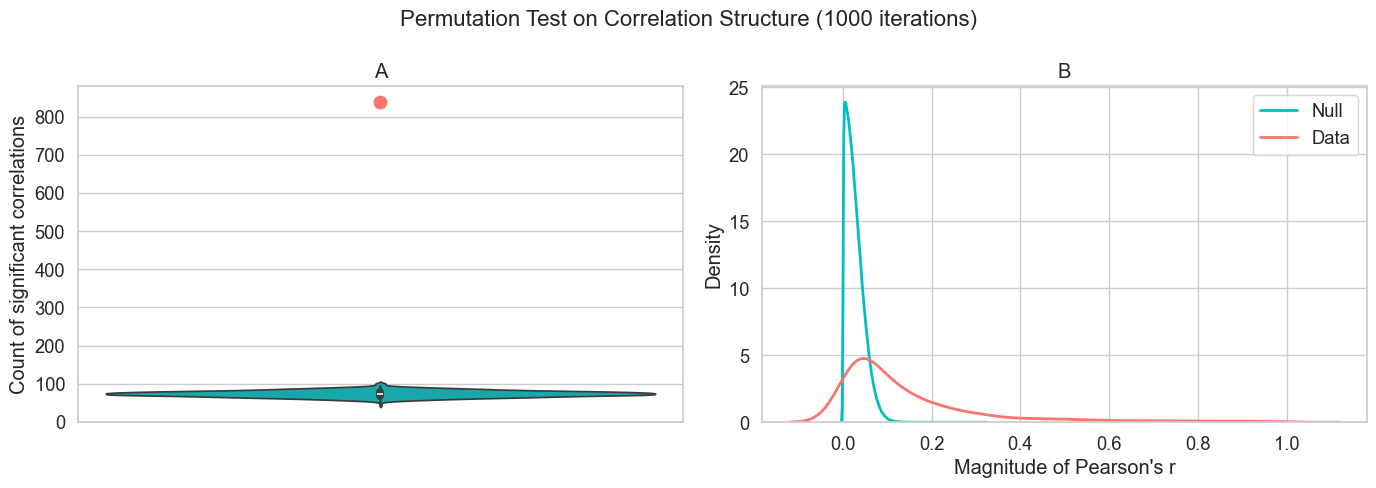

In [225]:
import matplotlib.pyplot as plt
import seaborn as sns

alpha = 0.05
obs_sig_count = np.sum(obs_pvals < alpha)
obs_abs_rs = np.abs(obs_rs)


plt.figure(figsize=(14, 5))

# Panel A: Count of significant correlations
plt.subplot(1, 2, 1)
sns.violinplot(y=null_sig_counts, color="#00BFC4")
plt.scatter([0], [obs_sig_count], color="#F8766D", s=80, zorder=5)
plt.ylabel("Count of significant correlations")
plt.title("A")

# Panel B: Magnitude of correlations
plt.subplot(1, 2, 2)
sns.kdeplot(null_rs_all, color="#00BFC4", linewidth=2, label="Null")
sns.kdeplot(obs_abs_rs, color="#F8766D", linewidth=2, label="Data")
plt.xlabel("Magnitude of Pearson's r")
plt.ylabel("Density")
plt.legend()
plt.title("B")

plt.suptitle("Permutation Test on Correlation Structure (1000 iterations)", fontsize=16)
plt.tight_layout()

# save the plot
plt.savefig(os.path.join(curfolder, "plots", "permutation_test_correlations.png"), dpi=300, bbox_inches='tight')
plt.show()


In [226]:
X_raw = df_numerical #df_clean .iloc[:, :-1].values
feature_names = df_numerical.columns.to_list()

obs_corrs = []

for i in range(X_raw.shape[1]):
    for j in range(i+1, X_raw.shape[1]):
        r, p = pearsonr(X_raw.iloc[:, i], X_raw.iloc[:, j])
        obs_corrs.append({
            "feat1": feature_names[i],
            "feat2": feature_names[j],
            "r": r,
            "abs_r": abs(r),
            "p": p
        })

obs_corrs_df = pd.DataFrame(obs_corrs)

alpha = 0.05

obs_sig_count = np.sum(obs_corrs_df["p"] < alpha)

print("Correlation test results.")
print(f"Count of significant pairwise correlations in original data at alpha = {alpha}: {obs_sig_count}")
print(f"Mean significant pairwise correlations in permuted data (n = 1000) at alpha = {alpha}: {null_sig_counts.mean():.3f}")
print(f"Min = {null_sig_counts.min()}, Max = {null_sig_counts.max()}.")

top_n = 5

top_corrs = obs_corrs_df.sort_values("abs_r", ascending=False).head(top_n)

print("\nTop 5 pairwise correlations in original data:")
for _, row in top_corrs.iterrows():
    print(f"{row['feat1']}, {row['feat2']}: {row['r']:.2f}")



Correlation test results.
Count of significant pairwise correlations in original data at alpha = 0.05: 840
Mean significant pairwise correlations in permuted data (n = 1000) at alpha = 0.05: 73.839
Min = 43, Max = 101.

Top 5 pairwise correlations in original data:
gross__rhythm__band1_band_power_totalarm, gross__rhythm__band2_band_power_totalarm: -1.00
fine__variability__fingertip_spread_std, fine__handshape__thumb_index_mean: 0.97
gross__rhythm__band2_centroid_totalarm, gross__rhythm__band2_entropy_totalarm: 0.96
gross__magnitude__arm_acc_peak_mean, gross__rhythm__arm_acc_mod_depth: 0.95
gross__rhythm__band3_centroid_totalarm, gross__rhythm__band3_entropy_totalarm: 0.94


# PCA all froups (fine + gross)

<br>
Now, we first standardize the data and apply PCA to extract principal components. We use custom function  (adapted from [here](https://stackoverflow.com/questions/50796024/feature-variable-importance-after-a-pca-analysis)) to visualize the first two principal components. Data points are color-coded on the target variable (groupID) and red arrows represent the contributions of selected variables to the PC.

## Interactive Biplot

In [81]:
def interactive_PCA_biplot(score, coeff, labels=None, y=None, selected_vars=None, 
                            arrow_strength=None, pc_x=1, pc_y=2, show_labels=True,
                            concepts=None, highlight_concepts=None, le=None):
    ix, iy = pc_x - 1, pc_y - 1
    xs = score[:, ix]
    ys = score[:, iy]
    concepts = np.array(concepts) if concepts is not None else None

    if concepts is not None and len(concepts) != len(xs):
        print(f"Warning: concepts length ({len(concepts)}) doesn't match score rows ({len(xs)}). Ignoring concepts.")
        concepts = None

    def group_name(g):
        return le.inverse_transform([g])[0] if le is not None else f"Group {g}"

    # --- Discrete color mapping per group ---
    groups = np.unique(y)
    palette = [
        '#1f77b4', '#ff7f0e', '#2ca02c', '#d62728',
        '#9467bd', '#8c564b', '#e377c2', '#7f7f7f'
    ]
    color_map = {g: palette[i % len(palette)] for i, g in enumerate(groups)}

    traces = []

    # --- One scatter trace per group ---
    for g in groups:
        mask = y == g
        traces.append(go.Scatter(
            x=xs[mask], y=ys[mask],
            mode='markers',
            marker=dict(size=8, color=color_map[g], opacity=0.6),
            name=group_name(g),
            text=[group_name(g) + (f"<br>{concepts[i]}" if concepts is not None else "")
                  for i in np.where(mask)[0]],
            hoverinfo='text',
            showlegend=True
        ))

    # --- Highlighted concept overlays ---
    if concepts is not None and highlight_concepts is not None:
        for concept in highlight_concepts:
            mask = np.where(concepts == concept)[0]

            seen_groups = {}
            for idx in mask:
                group = y[idx]
                if group not in seen_groups:
                    seen_groups[group] = idx

            representative_indices = list(seen_groups.values())

            traces.append(go.Scatter(
                x=xs[representative_indices],
                y=ys[representative_indices],
                mode='markers',
                marker=dict(size=12, color='red', symbol='star',
                            line=dict(color='black', width=1)),
                name=concept,
                text=[f"{concept} — {group_name(y[i])}" for i in representative_indices],
                hoverinfo='text',
                showlegend=True
            ))

    # --- Arrows ---
    vars_to_plot = selected_vars if selected_vars is not None else range(coeff.shape[0])
    base_scale = 10

    for i in vars_to_plot:
        var_name = f"Var{i+1}" if labels is None else labels[i]
        scale = base_scale * (arrow_strength.get(var_name, 1.0) if arrow_strength else 1.0)

        traces.append(go.Scatter(
            x=[0, coeff[i, ix] * scale],
            y=[0, coeff[i, iy] * scale],
            mode='lines+markers+text' if show_labels else 'lines+markers',
            line=dict(color='black'),
            marker=dict(size=4),
            text=[None, var_name] if show_labels else None,
            textposition='top center',
            hovertext=var_name,
            hoverinfo='text',
            showlegend=False
        ))

    layout = go.Layout(
        title=f"Interactive PCA Biplot — PC{pc_x} vs PC{pc_y}",
        xaxis=dict(title=f'PC{pc_x}'),
        yaxis=dict(title=f'PC{pc_y}'),
        width=900, height=700,
        hovermode='closest',
    )

    go.Figure(data=traces, layout=layout).show()

In [82]:
# make concepts as list
concepts = df_clean['concept'].tolist()
# now get rid of concept col
df_clean = df_clean.drop(columns=['concept'])

In [83]:
print(f"concepts: {len(concepts)}, df_clean rows: {len(df_clean)}")  # sanity check


concepts: 902, df_clean rows: 902


In [230]:
# save it 

df_clean.to_csv(os.path.join(curfolder, 'Datasets', 'sampled_merged_sapiens_cleanforPCA_noprune.csv'), index=False)

In [84]:
# read it
df_clean = pd.read_csv(os.path.join(curfolder, 'Datasets', 'sampled_merged_sapiens_cleanforPCA_noprune.csv'))

In [85]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import to_rgba
# import for go
import plotly.graph_objects as go


def static_PCA_biplot(score, coeff, labels=None, y=None, selected_vars=None,
                      arrow_strength=None, pc_x=1, pc_y=2, show_labels=True,
                      concepts=None, highlight_concepts=None, le=None,
                      figsize=(12, 9), save_path=None, dpi=300):
    """
    Presentation-quality static PCA biplot with centroids.

    Parameters
    ----------
    score           : np.ndarray, shape (n_samples, n_components)
    coeff           : np.ndarray, shape (n_vars, n_components)
    labels          : list of str, variable names for arrows
    y               : np.ndarray, group labels (int or str)
    selected_vars   : list of int, indices of variables to draw arrows for
    arrow_strength  : dict {var_name: scale_factor}
    pc_x, pc_y      : int, which PCs to plot (1-indexed)
    show_labels     : bool, annotate arrow tips with variable names
    concepts        : np.ndarray, concept label per sample
    highlight_concepts : list of str, concepts to highlight with star markers
    le              : sklearn LabelEncoder for decoding group labels
    figsize         : tuple
    save_path       : str or None — if given, saves figure to this path
    dpi             : int, resolution for saved figure
    """

    ix, iy = pc_x - 1, pc_y - 1
    xs = score[:, ix]
    ys = score[:, iy]
    concepts = np.array(concepts) if concepts is not None else None

    if concepts is not None and len(concepts) != len(xs):
        print(f"Warning: concepts length ({len(concepts)}) doesn't match score rows ({len(xs)}). Ignoring.")
        concepts = None

    def group_name(g):
        return le.inverse_transform([g])[0] if le is not None else f"Group {g}"

    # ── Palette ───────────────────────────────────────────────────────────────
    PALETTE = [
        "#4C72B0", "#DD8452", "#55A868", "#C44E52",
        "#8172B3", "#937860", "#DA8BC3", "#8C8C8C",
    ]
    groups = np.unique(y)
    color_map = {g: PALETTE[i % len(PALETTE)] for i, g in enumerate(groups)}

    # ── Figure setup ──────────────────────────────────────────────────────────
    fig, ax = plt.subplots(figsize=figsize, facecolor="#FAFAFA")
    ax.set_facecolor("#FAFAFA")

    for spine in ax.spines.values():
        spine.set_linewidth(0.8)
        spine.set_color("#CCCCCC")

    ax.axhline(0, color="#CCCCCC", linewidth=0.8, zorder=0)
    ax.axvline(0, color="#CCCCCC", linewidth=0.8, zorder=0)
    ax.grid(True, linestyle="--", linewidth=0.5, color="#E0E0E0", zorder=0)

    # ── Scatter per group ─────────────────────────────────────────────────────
    for g in groups:
        mask = y == g
        c = color_map[g]
        ax.scatter(
            xs[mask], ys[mask],
            color=to_rgba(c, 0.55),
            edgecolors=to_rgba(c, 0.85),
            linewidths=0.5,
            s=85,
            zorder=2,
            label=group_name(g),
        )

    # ── Centroids ─────────────────────────────────────────────────────────────
    for g in groups:
        mask = y == g
        cx, cy = xs[mask].mean(), ys[mask].mean()
        c = color_map[g]
        ax.scatter(
            cx, cy,
            color=c,
            edgecolors="white",
            linewidths=1.8,
            s=200,
            marker="X",
            zorder=5,
        )
        ax.annotate(
            group_name(g),
            xy=(cx, cy),
            xytext=(6, 6),
            textcoords="offset points",
            fontsize=9,
            fontweight="bold",
            color=c,
            zorder=6,
        )

    # ── Highlighted concepts ──────────────────────────────────────────────────
    if concepts is not None and highlight_concepts is not None:
        for concept in highlight_concepts:
            idx_all = np.where(concepts == concept)[0]
            seen_groups = {}
            for idx in idx_all:
                g = y[idx]
                if g not in seen_groups:
                    seen_groups[g] = idx
            rep_indices = list(seen_groups.values())

            ax.scatter(
                xs[rep_indices], ys[rep_indices],
                color="crimson",
                edgecolors="black",
                linewidths=0.8,
                s=180,
                marker="*",
                zorder=7,
                label=concept,
            )

    # ── Arrows ────────────────────────────────────────────────────────────────
    vars_to_plot = selected_vars if selected_vars is not None else range(coeff.shape[0])
    base_scale = 10

    arrowprops = dict(
        arrowstyle="-|>",
        color="#2B2B2B",
        lw=1.5,
        mutation_scale=12,
    )

    for i in vars_to_plot:
        var_name = f"Var{i+1}" if labels is None else labels[i]
        scale = base_scale * (arrow_strength.get(var_name, 1.0) if arrow_strength else 1.0)
        ex, ey = coeff[i, ix] * scale, coeff[i, iy] * scale

        ax.annotate(
            "",
            xy=(ex, ey),
            xytext=(0, 0),
            arrowprops=arrowprops,
            zorder=4,
        )

        if show_labels:
            # Nudge label slightly beyond arrow tip
            offset = 0.05 * np.array([ex, ey])
            ax.text(
                ex + offset[0], ey + offset[1],
                var_name,
                fontsize=8.5,
                ha="center",
                va="center",
                color="#2B2B2B",
                fontweight="semibold",
                bbox=dict(
                    boxstyle="round,pad=0.2",
                    facecolor="white",
                    edgecolor="none",
                    alpha=0.75,
                ),
                zorder=5,
            )

    # ── Labels & title ────────────────────────────────────────────────────────
    ax.set_xlabel(f"PC{pc_x}", fontsize=13, labelpad=8, color="#333333")
    ax.set_ylabel(f"PC{pc_y}", fontsize=13, labelpad=8, color="#333333")
    ax.set_title(
        f"PCA Biplot — PC{pc_x} vs PC{pc_y}",
        fontsize=15,
        fontweight="bold",
        color="#1A1A1A",
        pad=14,
    )
    ax.tick_params(colors="#555555", labelsize=9)

    # ── Legend (groups only, centroids explained in title note) ───────────────
    group_handles = [
        mpatches.Patch(color=color_map[g], label=group_name(g), alpha=0.8)
        for g in groups
    ]
    centroid_handle = plt.Line2D(
        [0], [0],
        marker="X",
        color="w",
        markerfacecolor="#555555",
        markeredgecolor="white",
        markersize=9,
        label="Centroid",
    )
    handles = group_handles + [centroid_handle]

    if concepts is not None and highlight_concepts is not None:
        for concept in highlight_concepts:
            handles.append(
                plt.Line2D(
                    [0], [0],
                    marker="*",
                    color="w",
                    markerfacecolor="crimson",
                    markeredgecolor="black",
                    markersize=11,
                    label=concept,
                )
            )

    ax.legend(
        handles=handles,
        loc="best",
        fontsize=9,
        framealpha=0.9,
        edgecolor="#CCCCCC",
        fancybox=False,
    )

    plt.tight_layout()

    if save_path:
        fig.savefig(save_path, dpi=dpi, bbox_inches="tight", facecolor=fig.get_facecolor())
        print(f"Figure saved to: {save_path}")

    plt.show()
    return fig, ax

## PC1-PC2

In [86]:
feature_names = df_clean.columns[:-1].to_list()

# Prepare data
X = df_clean.iloc[:, :-1].values  # All columns except the last as features
y = df_clean.iloc[:, -1].values   # Last column as target variable

# Convert categorical target to numeric if necessary
if y.dtype == 'object' or y.dtype.name == 'category':
    le = LabelEncoder()
    y = le.fit_transform(y)  # Converts categorical labels into numeric labels

# Scale the data
scaler_GS = StandardScaler()
Xz_GS = scaler_GS.fit_transform(X)    

# PCA transformation
pca_GS = PCA()
x_new_GS = pca_GS.fit_transform(Xz_GS)

# Get the PCA loadings (components_ is shape: [n_components, n_features])
loadings_GS = pca_GS.components_.T

# Number of top variables to show per PC
top_n = 10

# Get top variables per PC by absolute contribution
top_vars = set()
for i in range(2):  # for PC1, PC2, PC3
    component = loadings_GS[i]
    top_indices = np.argsort(np.abs(component))[-top_n:]
    top_vars.update(top_indices)

# Convert to sorted list for consistency
selected_vars = sorted(top_vars)

# Plot
interactive_PCA_biplot(score=x_new_GS, 
                       coeff=loadings_GS, 
                       labels=feature_names, 
                       y=y, 
                       selected_vars=selected_vars, 
                       pc_x=1, pc_y=2,
                       show_labels=False,
                       concepts=concepts,
                       highlight_concepts=None  # or None for no highlighting
                    
                    )

## PC2-PC3

In [19]:
interactive_PCA_biplot(score=x_new_GS, 
                       coeff=loadings_GS, 
                       labels=feature_names, 
                       y=y, 
                       selected_vars=selected_vars, 
                       pc_x=2, 
                       pc_y=3,
                       concepts = concepts,
                       show_labels=False)

## PC3-PC4

In [20]:
interactive_PCA_biplot(score=x_new_GS, 
                       coeff=loadings_GS, 
                       labels=feature_names, 
                       y=y, 
                       selected_vars=selected_vars, 
                       pc_x=3, 
                       pc_y=4,
                       show_labels=False)

## P4-P5

In [21]:
interactive_PCA_biplot(score=x_new_GS, 
                       coeff=loadings_GS, 
                       labels=feature_names, 
                       y=y, 
                       selected_vars=selected_vars, 
                       pc_x=4, 
                       pc_y=5,
                       show_labels=False)

In [22]:
print("Unique levels in target column:", np.unique(df_clean.iloc[:, -1]))

Unique levels in target column: ['Gesture' 'Learner_1' 'Learner_2' 'Sign']


## Bootstrap PCA

In [23]:

def bootstrap_pca(Xz, n_boot=1000):

    rng = np.random.default_rng(42)

    boot_loadings = []
    boot_eigs = []

    n = Xz.shape[0]

    for _ in range(n_boot):
        idx = rng.choice(n, n, replace=True)
        Xb = Xz[idx]
        pca_b = PCA().fit(Xb)
        boot_loadings.append(pca_b.components_.T)
        boot_eigs.append(pca_b.explained_variance_)

    boot_loadings = np.array(boot_loadings)
    boot_eigs = np.array(boot_eigs)

    # total variance per bootstrap PCA (needed to convert eigvals -> variance explained)
    boot_total_var = np.sum(boot_eigs, axis=1, keepdims=True)

    # bootstrap variance explained per PC
    boot_var_explained = boot_eigs / boot_total_var

    # mean and SD of bootstrap variance explained
    boot_var_mean = boot_var_explained.mean(axis=0)
    boot_var_sd = boot_var_explained.std(axis=0)

    # # sanity check shapes
    # print(boot_var_mean.shape, boot_var_sd.shape)

    loading_ci_low = np.percentile(boot_loadings, 5, axis=0)
    loading_ci_high = np.percentile(boot_loadings, 95, axis=0)

    eig_ci_low = np.percentile(boot_eigs, 2.5, axis=0)
    eig_ci_high = np.percentile(boot_eigs, 97.5, axis=0)

    # bind all results into a dictionary for easy access
    results = {
        "boot_loadings": boot_loadings,
        "boot_eigs": boot_eigs,
        "boot_var_mean": boot_var_mean,
        "boot_var_sd": boot_var_sd,
        "loading_ci_low": loading_ci_low,
        "loading_ci_high": loading_ci_high,
        "eig_ci_low": eig_ci_low,
        "eig_ci_high": eig_ci_high
    }

    return results

bootstrap_results_GS = bootstrap_pca(Xz_GS)


## Null PCA (permutation test)

In [24]:
from unittest import result


def permutation_pca(Xz, n_boot=1000):

    rng = np.random.default_rng(42)

    null_loadings = []
    null_eigs = []

    for _ in range(n_boot):
        #
        Xnull = np.apply_along_axis(rng.permutation, 0, Xz)
        pca_n = PCA().fit(Xnull)
        null_loadings.append(pca_n.components_.T)
        null_eigs.append(pca_n.explained_variance_)

    null_loadings = np.array(null_loadings)
    null_eigs = np.array(null_eigs)

    null_loading_thresh = np.percentile(np.abs(null_loadings), 95, axis=0)
    null_eig_thresh = np.percentile(null_eigs, 95, axis=0)

    results = {
        "null_loadings": null_loadings,
        "null_eigs": null_eigs,
        "null_loading_thresh": null_loading_thresh,
        "null_eig_thresh": null_eig_thresh
    }

    return results

permutation_results_GS = permutation_pca(Xz_GS)


## Significance mask

In [25]:
# determine significant PCs
var_explained_GS = pca_GS.explained_variance_ratio_
null_var_thresh_GS = permutation_results_GS["null_eig_thresh"] / np.sum(pca_GS.explained_variance_)  # convert eig to variance ratio
sig_pc_null_GS = var_explained_GS > null_var_thresh_GS



In [26]:
# apply 5-10 % cut-off
sig_pc_effect_GS = var_explained_GS > 0.05  # 5% cut-off
sig_pc_GS = sig_pc_null_GS & sig_pc_effect_GS

print("Significant PCs:")
for i, sig in enumerate(sig_pc_GS, start=1):
    print(f"PC{i}: significant = {sig}, var explained = {var_explained_GS[i-1]:.3f}")



Significant PCs:
PC1: significant = True, var explained = 0.148
PC2: significant = True, var explained = 0.118
PC3: significant = True, var explained = 0.110
PC4: significant = True, var explained = 0.076
PC5: significant = True, var explained = 0.054
PC6: significant = False, var explained = 0.047
PC7: significant = False, var explained = 0.038
PC8: significant = False, var explained = 0.035
PC9: significant = False, var explained = 0.030
PC10: significant = False, var explained = 0.029
PC11: significant = False, var explained = 0.026
PC12: significant = False, var explained = 0.023
PC13: significant = False, var explained = 0.020
PC14: significant = False, var explained = 0.019
PC15: significant = False, var explained = 0.018
PC16: significant = False, var explained = 0.016
PC17: significant = False, var explained = 0.015
PC18: significant = False, var explained = 0.015
PC19: significant = False, var explained = 0.014
PC20: significant = False, var explained = 0.014
PC21: significant

In [341]:
import os
sig_idx = np.where(sig_pc_GS)[0]                       # significant PCs (null AND >=5%)
pc_cols = [f"PC{i+1}" for i in sig_idx]
scores  = pd.DataFrame(x_new_GS[:, sig_idx], columns=pc_cols)

# metadata MUST be the same rows, same order, that went into pca_GS.fit_transform(Xz_GS).
# NOTE: clean_df() drops the participant column ('group'), so pull metadata from sampled_df
# (post-LP-removal, post-dropna) which still has group / groupID / concept.
meta = (sampled_df[['group', 'groupID', 'concept']]
        .reset_index(drop=True)
        .rename(columns={'group': 'participant'}))
assert len(meta) == len(scores), "row mismatch — metadata not aligned with PCA scores!"
# optional strong check: groupID order matches the PCA target
# assert (meta['groupID'].values == df_clean.iloc[:, -1].values).all()

out = pd.concat([scores, meta], axis=1)
for row in out.itertuples():
    if row.participant.startswith('IP'):
        out.loc[row.Index, 'participant'] = row.participant.split('_')[0]

out.to_csv(os.path.join(curfolder, 'Datasets', 'pca_scores_for_brms.csv'), index=False)

In [27]:
import matplotlib.pyplot as plt
import numpy as np

def plot_pca_variance(var_explained,
                             boot_ci_low,
                             boot_ci_high,
                             null_thresh,
                             max_pcs=20):
    """
    var_explained: array of variance explained ratios (e.g. pca.explained_variance_ratio_)
    boot_ci_low: bootstrap CI lower bound (variance ratio)
    boot_ci_high: bootstrap CI upper bound (variance ratio)
    null_thresh: null 95% threshold (variance ratio)
    """

    pcs = np.arange(1, len(var_explained) + 1)

    # optionally truncate to first N PCs (keeps plot readable)
    pcs = pcs[:max_pcs]
    var_explained = var_explained[:max_pcs]
    boot_ci_low = boot_ci_low[:max_pcs]
    boot_ci_high = boot_ci_high[:max_pcs]

    plt.figure(figsize=(10, 6))

    # CI bars
    plt.vlines(
        pcs,
        boot_ci_low * 100,
        boot_ci_high * 100,
        colors='black',
        linewidth=1,
        alpha=0.7
    )

    # observed variance points
    plt.scatter(
        pcs,
        var_explained * 100,
        color='red',
        s=40,
        zorder=3,
        label="Sampling"
    )

    # null threshold line
    plt.plot(
    pcs,
    null_thresh[:len(pcs)] * 100,
    linestyle='--',
    color='teal',
    linewidth=2,
    label="Null"
)


    plt.xlabel("Principal Component")
    plt.ylabel("Variance Explained (%)")
    plt.title("Variance Explained by Principal Components")

    plt.xticks(pcs, [f"PC{i}" for i in pcs], rotation=90)
    plt.legend()
    plt.tight_layout()
    plt.show()


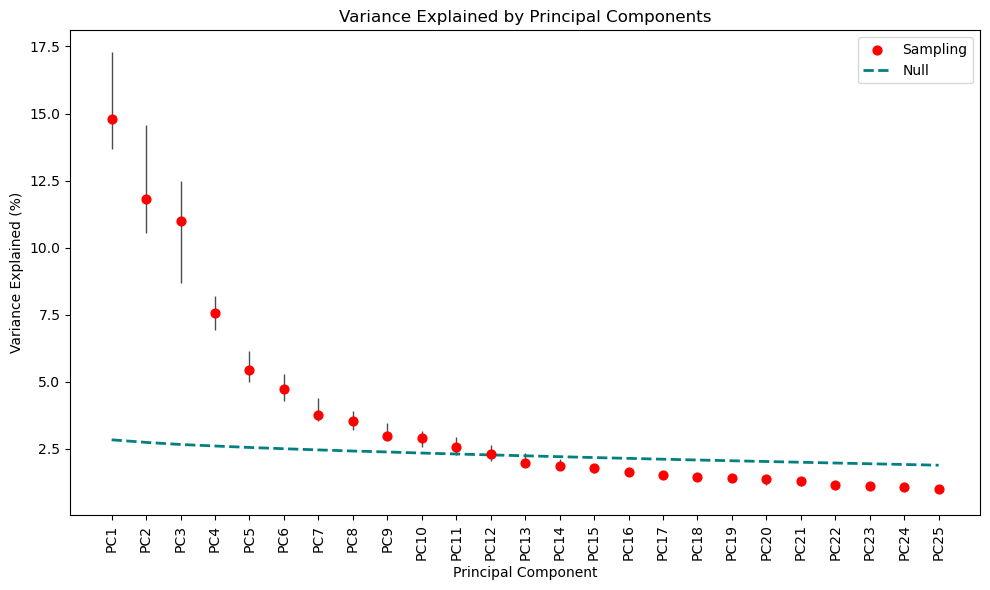

<Figure size 640x480 with 0 Axes>

In [28]:
boot_var_ci_low_GS = bootstrap_results_GS["eig_ci_low"] / np.sum(pca_GS.explained_variance_)
boot_var_ci_high_GS = bootstrap_results_GS["eig_ci_high"] / np.sum(pca_GS.explained_variance_)
null_var_thresh_GS = permutation_results_GS["null_eig_thresh"] / np.sum(pca_GS.explained_variance_)

plot_pca_variance(
    var_explained=pca_GS.explained_variance_ratio_,
    boot_ci_low=boot_var_ci_low_GS,
    boot_ci_high=boot_var_ci_high_GS,
    null_thresh=null_var_thresh_GS,
    max_pcs=25   # adjust for readability
)

# save this plot
plt.savefig(os.path.join(curfolder, "plots", "GS_all_pca_variance_explained.png"), dpi=300, bbox_inches='tight')



In [29]:
import pandas as pd
import numpy as np

# number of PCs
n_pcs = len(pca_GS.explained_variance_ratio_)

pc_names = [f"PC{i+1}" for i in range(n_pcs)]

df_variance_GS = pd.DataFrame({
    "PC": pc_names,
    "variance_explained": pca_GS.explained_variance_ratio_,
    "low_confint_var": boot_var_ci_low_GS,
    "high_confint_var": boot_var_ci_high_GS,
    "mean_confint_var": bootstrap_results_GS["boot_var_mean"],
    "sd_confint_var": bootstrap_results_GS["boot_var_sd"],
    "null_thresh": null_var_thresh_GS
})

# significance: observed variance > null threshold
df_variance_GS["sig_PC"] = df_variance_GS["variance_explained"] > df_variance_GS["null_thresh"]

# filter significant PCs
df_sig_pcs_GS = df_variance_GS.loc[df_variance_GS["sig_PC"], [
    "PC",
    "variance_explained",
    "low_confint_var",
    "high_confint_var",
    "mean_confint_var",
    "sd_confint_var"
]]

# convert to %
df_sig_pcs_GS.loc[:, df_sig_pcs_GS.columns != "PC"] *= 100

df_sig_pcs_GS


,PC,variance_explained,low_confint_var,high_confint_var,mean_confint_var,sd_confint_var
0,PC1,14.786962,13.682957,17.281736,15.248888,0.735747
1,PC2,11.794244,10.533620,14.579369,12.283268,0.720211
2,PC3,11.001954,8.675926,12.473590,10.499472,0.785771
3,PC4,7.554729,6.925498,8.210392,7.596494,0.354278
4,PC5,5.434020,5.002112,6.126365,5.545826,0.304194
5,PC6,4.744583,4.285273,5.287176,4.802363,0.263792
6,PC7,3.775259,3.514781,4.382572,3.940412,0.211319
7,PC8,3.531858,3.188411,3.916570,3.538225,0.160915
8,PC9,2.986927,2.822188,3.457964,3.121910,0.150006
9,PC10,2.883159,2.569399,3.172912,2.864950,0.122990


## Significant variables

Which variables are significant?

In [89]:
def identify_sigvar(pca, bootstrap_results, permutation_results, df_clean):

    # compute index loadings
    # pca.components_.T shape: (n_features, n_pcs)
    loadings = pca.components_.T
    eigs = pca.explained_variance_

    # index loadings for original PCA
    index_loadings = (loadings ** 2) * (eigs ** 2)

    # compute bootrap index loadings
    boot_index_loadings = (bootstrap_results["boot_loadings"] ** 2) * (bootstrap_results["boot_eigs"][:, None, :] ** 2)

    # 90% CI (matches loadings_confint = 0.9)
    low_q = 5
    high_q = 95

    boot_index_ci_low = np.percentile(boot_index_loadings, low_q, axis=0)
    boot_index_ci_high = np.percentile(boot_index_loadings, high_q, axis=0)

    # compute null index loadings
    null_index_loadings = (permutation_results["null_loadings"] ** 2) * (permutation_results["null_eigs"][:, None, :] ** 2)

    null_index_ci_low = np.percentile(null_index_loadings, low_q, axis=0)
    null_index_ci_high = np.percentile(null_index_loadings, high_q, axis=0)

    sig_vars = []

    for pc in range(loadings.shape[1]):
        for feat in range(loadings.shape[0]):
            sig_vars.append({
                "PC": pc + 1,
                "feature": df_clean.columns[feat],
                "loading": loadings[feat, pc],
                "index_loading": index_loadings[feat, pc],
                "low_confint": boot_index_ci_low[feat, pc],
                "high_confint": boot_index_ci_high[feat, pc],
                "low_null": null_index_ci_low[feat, pc],
                "high_null": null_index_ci_high[feat, pc],
                "sig_loading": index_loadings[feat, pc] > null_index_ci_high[feat, pc]
            })

    df_sig_vars = pd.DataFrame(sig_vars)

    return df_sig_vars




In [90]:
df_sig_vars_GS = identify_sigvar(pca_GS, bootstrap_results_GS, permutation_results_GS, df_clean)
df_sig_vars_GS[df_sig_vars_GS["sig_loading"]].sort_values(["PC", "index_loading"], ascending=[True, False])

,PC,feature,loading,index_loading,low_confint,high_confint,low_null,high_null,sig_loading
9,1,gross__magnitude__arm_acc_peak_mean,0.324953,6.999823,3.902643,8.324504,0.000185,0.142565,True
8,1,gross__variability__arm_acc_Gstd,0.321973,6.872056,3.553211,8.361492,0.000200,0.135681,True
1,1,gross__variability__arm_speed_Gstd,0.316317,6.632721,3.224425,8.543991,0.000195,0.142166,True
6,1,gross__rhythm__arm_speed_mod_depth,0.313074,6.497406,3.592006,7.712133,0.000217,0.142484,True
2,1,gross__magnitude__arm_speed_peak_mean,0.313036,6.495834,3.207748,8.203029,0.000124,0.154669,True
...,...,...,...,...,...,...,...,...,...
1038,19,fine__smoothness__flexion_jerk,0.390708,0.090689,0.000178,0.163191,0.000091,0.080756,True
1181,22,gross__rhythm__band3_dom_freq_totalarm,0.483080,0.095608,0.000164,0.112791,0.000087,0.081536,True
1260,23,fine__coordination__corr_index_middle,0.459044,0.081173,0.000193,0.068882,0.000129,0.070916,True
1319,24,fine__variability__flexion_entropy,0.441841,0.065842,0.000132,0.066556,0.000087,0.065831,True


In [91]:
for pc in df_sig_pcs_GS["PC"]:
    pc_no = int(pc.replace("PC", ""))
    print(f"\nPC{pc_no} significant contributors:")
    display(
        df_sig_vars_GS[(df_sig_vars_GS["PC"] == pc_no) & (df_sig_vars_GS["sig_loading"])]
        .sort_values("index_loading", ascending=False)
        .head(10)
    )



PC1 significant contributors:


,PC,feature,loading,index_loading,low_confint,high_confint,low_null,high_null,sig_loading
9,1,gross__magnitude__arm_acc_peak_mean,0.324953,6.999823,3.902643,8.324504,0.000185,0.142565,True
8,1,gross__variability__arm_acc_Gstd,0.321973,6.872056,3.553211,8.361492,0.000200,0.135681,True
1,1,gross__variability__arm_speed_Gstd,0.316317,6.632721,3.224425,8.543991,0.000195,0.142166,True
6,1,gross__rhythm__arm_speed_mod_depth,0.313074,6.497406,3.592006,7.712133,0.000217,0.142484,True
2,1,gross__magnitude__arm_speed_peak_mean,0.313036,6.495834,3.207748,8.203029,0.000124,0.154669,True
13,1,gross__rhythm__arm_acc_mod_depth,0.305399,6.182748,3.526576,7.223407,0.000201,0.141125,True
7,1,gross__magnitude__arm_acc_Gmean,0.217405,3.133193,1.147535,4.783866,0.000113,0.154603,True
30,1,gross__magnitude__bbmv_arms_total,0.162676,1.754251,0.331003,3.619751,0.000212,0.158827,True
15,1,gross__rhythm__arm_speed_sampen,-0.160032,1.697704,0.566274,3.163807,0.000137,0.136867,True
5,1,gross__rhythm__arm_speed_peak_rate,-0.153265,1.557161,0.298112,3.493508,0.000214,0.160126,True



PC2 significant contributors:


,PC,feature,loading,index_loading,low_confint,high_confint,low_null,high_null,sig_loading
66,2,gross__rhythm__arm_acc_peak_n,0.302855,3.868115,0.127156,4.756474,0.000205,0.136163,True
59,2,gross__rhythm__arm_speed_peak_n,0.289563,3.536035,0.117429,4.562899,0.000139,0.139536,True
69,2,gross__magnitude__arm_speed_integral,0.287642,3.489264,0.017107,5.338806,0.000141,0.147963,True
79,2,gross__rhythm__band2_band_power_totalarm,0.267639,3.020843,0.039817,4.883986,0.000176,0.136514,True
75,2,gross__rhythm__band1_band_power_totalarm,-0.265308,2.968446,0.040853,4.848324,0.000167,0.145266,True
67,2,gross__rhythm__arm_acc_peak_rate,0.227183,2.176602,0.041766,3.394452,0.000235,0.136558,True
74,2,gross__rhythm__band1_centroid_totalarm,0.220058,2.042232,0.026286,2.833615,0.000109,0.144465,True
55,2,gross__magnitude__arm_speed_Gmean,0.219300,2.028179,0.012768,3.791902,0.000152,0.144802,True
76,2,gross__rhythm__band1_entropy_totalarm,0.189047,1.507194,0.019895,2.127757,0.000183,0.143893,True
85,2,gross__magnitude__bbmv_arms_total,0.188766,1.502710,0.013382,2.676432,0.000159,0.148406,True



PC3 significant contributors:


,PC,feature,loading,index_loading,low_confint,high_confint,low_null,high_null,sig_loading
145,3,fine__handshape__fingertip_spread_mean,0.309212,3.508649,0.006042,4.143913,0.000233,0.139198,True
147,3,fine__handshape__thumb_index_mean,0.298897,3.278476,0.008262,3.994284,0.000096,0.142949,True
155,3,fine__variability__handshape_variability,0.295968,3.214538,0.015146,3.946744,0.000142,0.128897,True
146,3,fine__variability__fingertip_spread_std,0.286651,3.015344,0.006924,3.802474,0.000182,0.145152,True
148,3,fine__variability__thumb_index_std,0.285523,2.991642,0.010251,3.719284,0.000206,0.139759,True
149,3,fine__handshape__mcp_tip_mean,0.281172,2.901174,0.008076,3.378736,0.000199,0.136855,True
156,3,fine__magnitude__flexion_speed_mean,0.272557,2.726106,0.184060,3.108284,0.000193,0.124685,True
150,3,fine__variability__mcp_tip_std,0.246551,2.230701,0.010311,2.693115,0.000186,0.148385,True
157,3,fine__variability__flexion_speed_std,0.240677,2.125671,0.022172,2.640381,0.000196,0.128408,True
151,3,fine__handshape__thumb_opposition_mean,0.196724,1.420178,0.002863,2.137124,0.000239,0.132099,True


... (14 outputs left out)


PC11 significant contributors:


,PC,feature,loading,index_loading,low_confint,high_confint,low_null,high_null,sig_loading
572,11,gross__rhythm__band2_dom_freq_totalarm,0.450844,0.400741,0.000762,0.490416,0.000116,0.104864,True
574,11,gross__rhythm__band2_band_power_totalarm,0.358480,0.253363,0.000709,0.272828,0.000097,0.106146,True
570,11,gross__rhythm__band1_band_power_totalarm,-0.351498,0.243589,0.001080,0.268422,0.000131,0.105902,True
553,11,gross__variability__arm_speed_peak_std,-0.321580,0.203887,0.002347,0.404336,0.000087,0.105094,True



PC12 significant contributors:


,PC,feature,loading,index_loading,low_confint,high_confint,low_null,high_null,sig_loading
638,12,gross__coordination__arm_asymmetry,0.467751,0.348398,0.003563,0.474496,0.000122,0.093095,True
639,12,gross__proxdist__proximalization_index,0.408690,0.265971,0.001993,0.433880,0.000156,0.108570,True
635,12,gross__magnitude__bbmv_arms_total,-0.301229,0.144491,0.002321,0.178892,0.000116,0.108107,True


In [33]:
import matplotlib.pyplot as plt

def plot_index_loadings(df_pc, pc_name="PC3"):
    plt.figure(figsize=(12, 6))

    x = np.arange(len(df_pc))

    # bootstrap CI
    plt.vlines(
        x,
        df_pc["boot_low"],
        df_pc["boot_high"],
        color="red",
        alpha=0.6,
        linewidth=2,
        label="Bootstrap CI"
    )

    # null threshold (mean across variables like R plot)
    plt.hlines(
        y=df_pc["null_thresh"].mean(),
        xmin=-1,
        xmax=len(df_pc),
        color="turquoise",
        linestyle="--",
        linewidth=2,
        label="Null threshold"
    )

    # observed index loadings
    for i, row in df_pc.iterrows():
        marker = "+" if row["loading_sign"] > 0 else "_"
        plt.plot(
            x[df_pc.index.get_loc(i)],
            row["obs_index"],
            marker=marker,
            color="black",
            markersize=10
        )

    plt.xticks(x, df_pc["variable"], rotation=90)
    plt.ylabel("Index Loading")
    plt.title(f"Index Loadings for {pc_name}\nBootstrap CIs + Permutation Null")
    plt.legend()
    plt.tight_layout()
    plt.show()


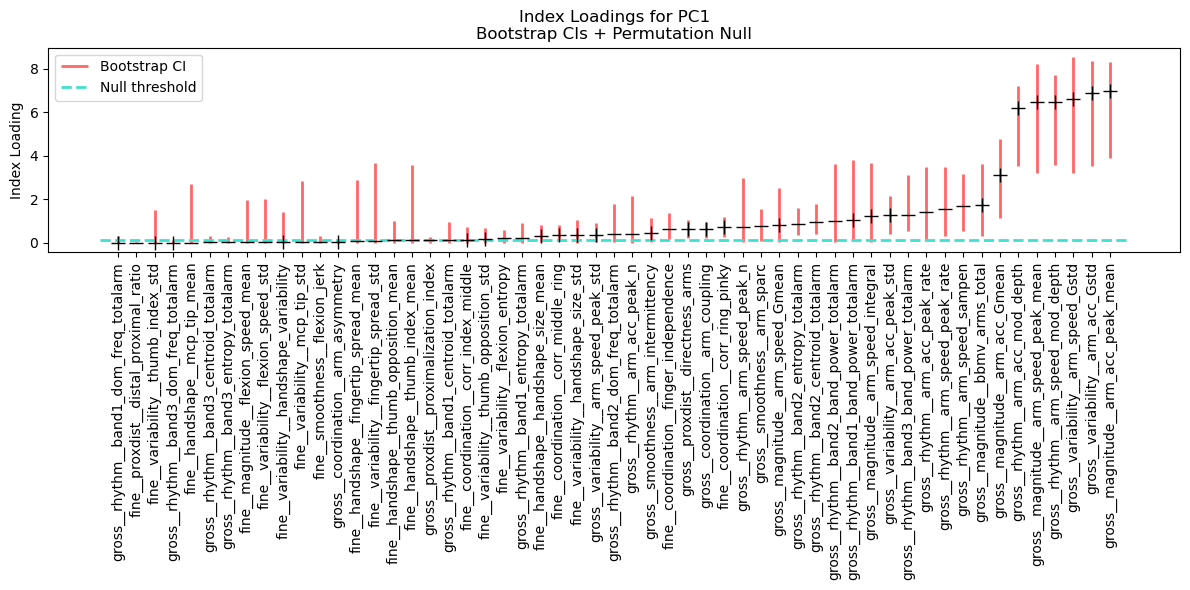

In [34]:
pc_idx = 0  # PC3 (0-based)

# observed
obs_loadings_GS = pca_GS.components_[pc_idx]
obs_eig_GS = pca_GS.explained_variance_[pc_idx]
obs_index_GS = (obs_loadings_GS**2) * (obs_eig_GS**2)

# bootstrap index loadings
boot_index_GS = (bootstrap_results_GS["boot_loadings"][:, :, pc_idx]**2) * (bootstrap_results_GS["boot_eigs"][:, pc_idx][:, None]**2)

boot_low_GS = np.percentile(boot_index_GS, 5, axis=0)
boot_high_GS = np.percentile(boot_index_GS, 95, axis=0)

# null index loadings
null_index_GS = (permutation_results_GS["null_loadings"][:, :, pc_idx]**2) * (permutation_results_GS["null_eigs"][:, pc_idx][:, None]**2)
null_thresh_GS = np.percentile(null_index_GS, 95, axis=0)

df_pc_GS = pd.DataFrame({
    "variable": df_clean.columns[:-1],
    "obs_index": obs_index_GS,
    "boot_low": boot_low_GS,
    "boot_high": boot_high_GS,
    "null_thresh": null_thresh_GS,
    "loading_sign": np.sign(obs_loadings_GS )
})

df_pc_GS = df_pc_GS.sort_values("obs_index")

plot_index_loadings(df_pc_GS, pc_name="PC1")



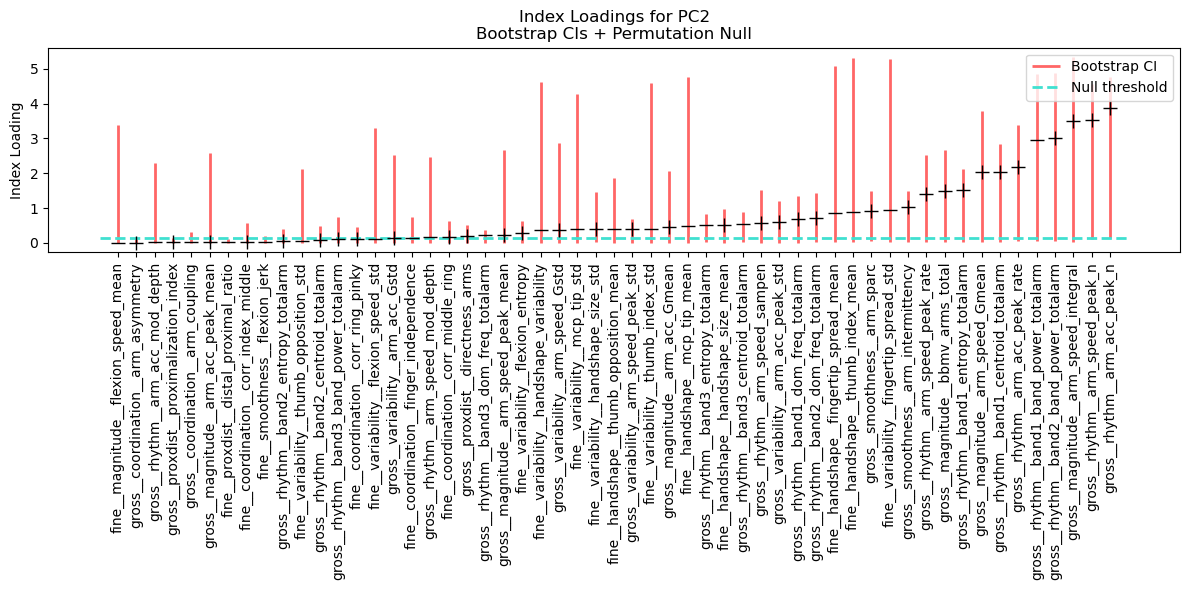

In [35]:
pc_idx = 1  # PC3 (0-based)

# observed
obs_loadings_GS = pca_GS.components_[pc_idx]
obs_eig_GS = pca_GS.explained_variance_[pc_idx]
obs_index_GS = (obs_loadings_GS**2) * (obs_eig_GS**2)

# bootstrap index loadings
boot_index_GS = (bootstrap_results_GS["boot_loadings"][:, :, pc_idx]**2) * (bootstrap_results_GS["boot_eigs"][:, pc_idx][:, None]**2)

boot_low_GS = np.percentile(boot_index_GS, 5, axis=0)
boot_high_GS = np.percentile(boot_index_GS, 95, axis=0)

# null index loadings
null_index_GS = (permutation_results_GS["null_loadings"][:, :, pc_idx]**2) * (permutation_results_GS["null_eigs"][:, pc_idx][:, None]**2)
null_thresh_GS = np.percentile(null_index_GS, 95, axis=0)

df_pc_GS = pd.DataFrame({
    "variable": df_clean.columns[:-1],
    "obs_index": obs_index_GS,
    "boot_low": boot_low_GS,
    "boot_high": boot_high_GS,
    "null_thresh": null_thresh_GS,
    "loading_sign": np.sign(obs_loadings_GS )
})

df_pc_GS = df_pc_GS.sort_values("obs_index")

plot_index_loadings(df_pc_GS, pc_name="PC2")



50% cumulative contribution

In [36]:
from operator import index


def top_until_50pct(index_loadings_pc, feature_names):
    total = index_loadings_pc.sum()
    df = pd.DataFrame({
        "feature": feature_names,
        "index_loading": index_loadings_pc
    }).sort_values("index_loading", ascending=False)
    
    df["cum_frac"] = df["index_loading"].cumsum() / total
    return df[df["cum_frac"] <= 0.5]

# Example for PC1
index_loadings_GS = (pca_GS.components_.T ** 2) * (pca_GS.explained_variance_ ** 2)
top_pc1 = top_until_50pct(index_loadings_GS[:, 0], df_clean.columns[:-1])
top_pc1



,feature,index_loading,cum_frac
9,gross__magnitude__arm_acc_peak_mean,6.999823,0.105594
8,gross__variability__arm_acc_Gstd,6.872056,0.209261
1,gross__variability__arm_speed_Gstd,6.632721,0.309318
6,gross__rhythm__arm_speed_mod_depth,6.497406,0.407333


## Plot only significant vars

### Biplot PC1-PC2

Figure saved to: c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\plots\PCA_GS_all_PC1_2_biplot.png


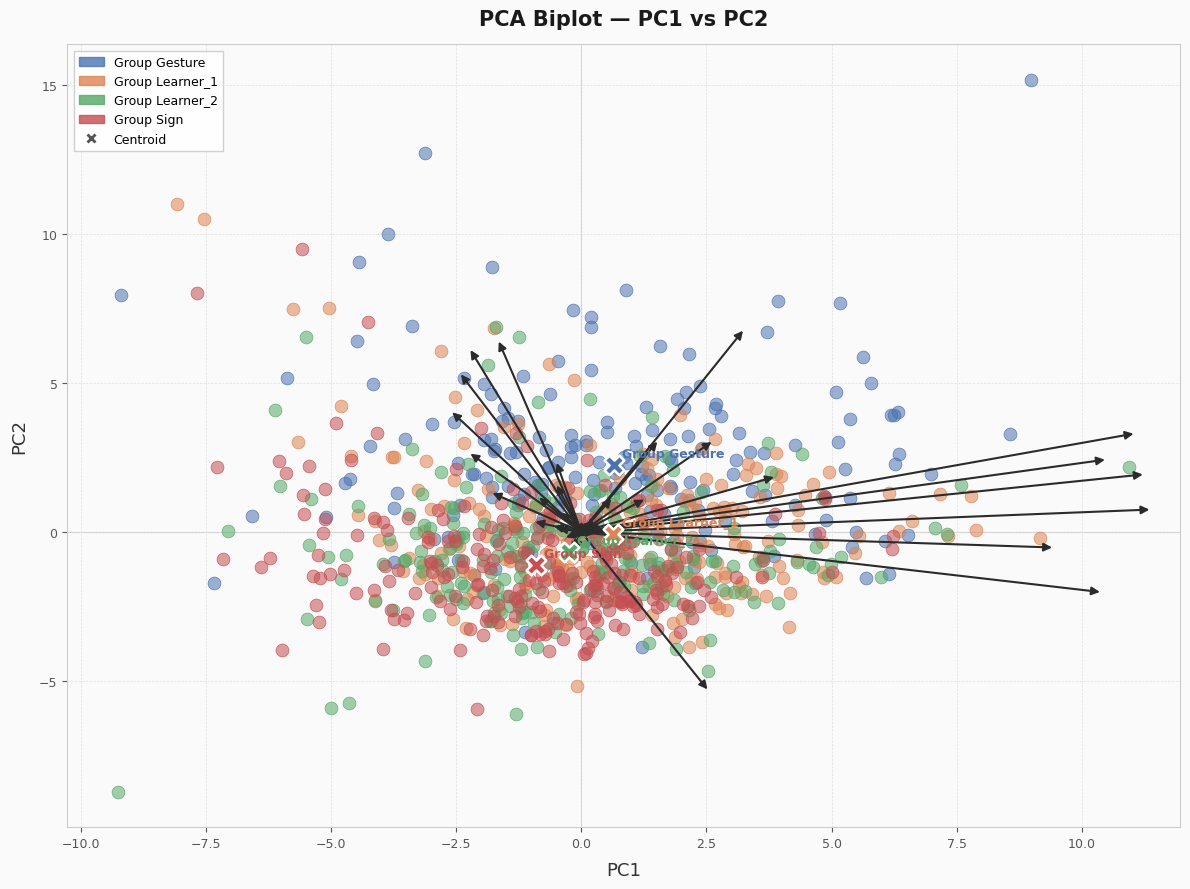

(<Figure size 1200x900 with 1 Axes>,
 <Axes: title={'center': 'PCA Biplot — PC1 vs PC2'}, xlabel='PC1', ylabel='PC2'>)

In [39]:
pcs_to_plot = [1, 2]  # PC1–PC2

sig_features_GS = (
    df_sig_vars_GS[
        (df_sig_vars_GS["sig_loading"]) &
        (df_sig_vars_GS["PC"].isin(pcs_to_plot))
    ]["feature"]
    .unique()
)

feature_names = df_clean.columns[:-1]
selected_vars = [feature_names.get_loc(f) for f in sig_features_GS if f in feature_names]

arrow_strength = (
    df_sig_vars_GS[df_sig_vars_GS["PC"].isin([1,2])]
    .groupby("feature")["index_loading"]
    .mean()
    .to_dict()
)

interactive_PCA_biplot(
    score=x_new_GS, 
    coeff=loadings_GS, 
    labels=feature_names, 
    y=y, 
    selected_vars=selected_vars, 
    pc_x=1, pc_y=2,
    show_labels=False,
    arrow_strength=arrow_strength
)

# static plot
static_PCA_biplot(
    score=x_new_GS, 
    coeff=loadings_GS, 
    labels=feature_names, 
    y=y, 
    selected_vars=selected_vars, 
    pc_x=1, pc_y=2,
    show_labels=False,
    arrow_strength=arrow_strength,
    save_path=os.path.join(curfolder, "plots", "PCA_GS_all_PC1_2_biplot.png")
)



### Biplot PC2-PC3

Figure saved to: c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\plots\PCA_GS_all_PC2_3_biplot.png


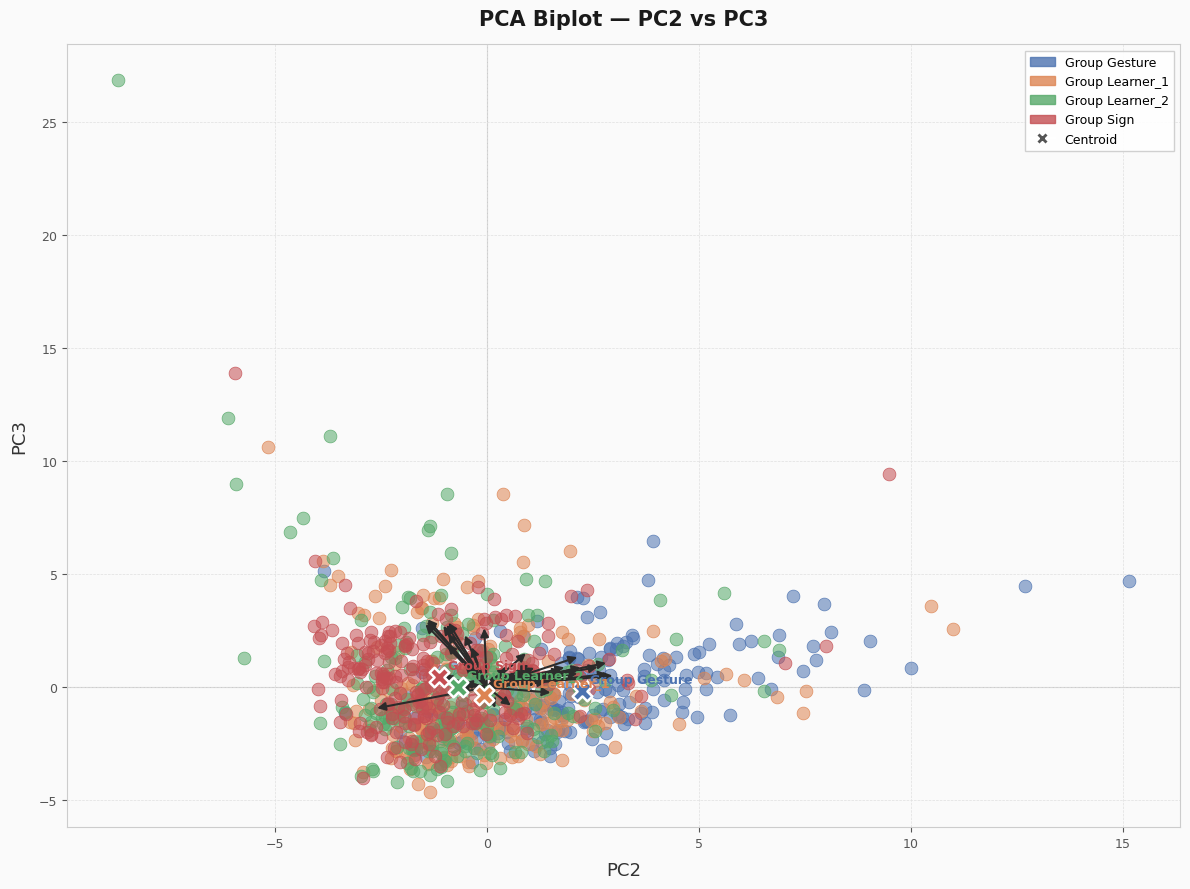

(<Figure size 1200x900 with 1 Axes>,
 <Axes: title={'center': 'PCA Biplot — PC2 vs PC3'}, xlabel='PC2', ylabel='PC3'>)

In [40]:
pcs_to_plot = [2, 3]  # PC1–PC2

sig_features_GS = (
    df_sig_vars_GS[
        (df_sig_vars_GS["sig_loading"]) &
        (df_sig_vars_GS["PC"].isin(pcs_to_plot))
    ]["feature"]
    .unique()
)

feature_names = df_clean.columns[:-1]
selected_vars = [feature_names.get_loc(f) for f in sig_features_GS if f in feature_names]

arrow_strength = (
    df_sig_vars_GS[df_sig_vars_GS["PC"].isin([pcs_to_plot])]
    .groupby("feature")["index_loading"]
    .mean()
    .to_dict()
)

interactive_PCA_biplot(
    score=x_new_GS, 
    coeff=loadings_GS, 
    labels=feature_names, 
    y=y, 
    selected_vars=selected_vars, 
    pc_x=pcs_to_plot[0], pc_y=pcs_to_plot[1],
    show_labels=False,
    arrow_strength=arrow_strength
)

# static plot
static_PCA_biplot(
    score=x_new_GS, 
    coeff=loadings_GS, 
    labels=feature_names, 
    y=y, 
    selected_vars=selected_vars, 
    pc_x=pcs_to_plot[0], pc_y=pcs_to_plot[1],
    show_labels=False,
    arrow_strength=arrow_strength,
    save_path=os.path.join(curfolder, "plots", "PCA_GS_all_PC2_3_biplot.png")
)


### Biplot PC1-PC3

Figure saved to: c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\plots\PCA_GS_all_PC1_3_biplot.png


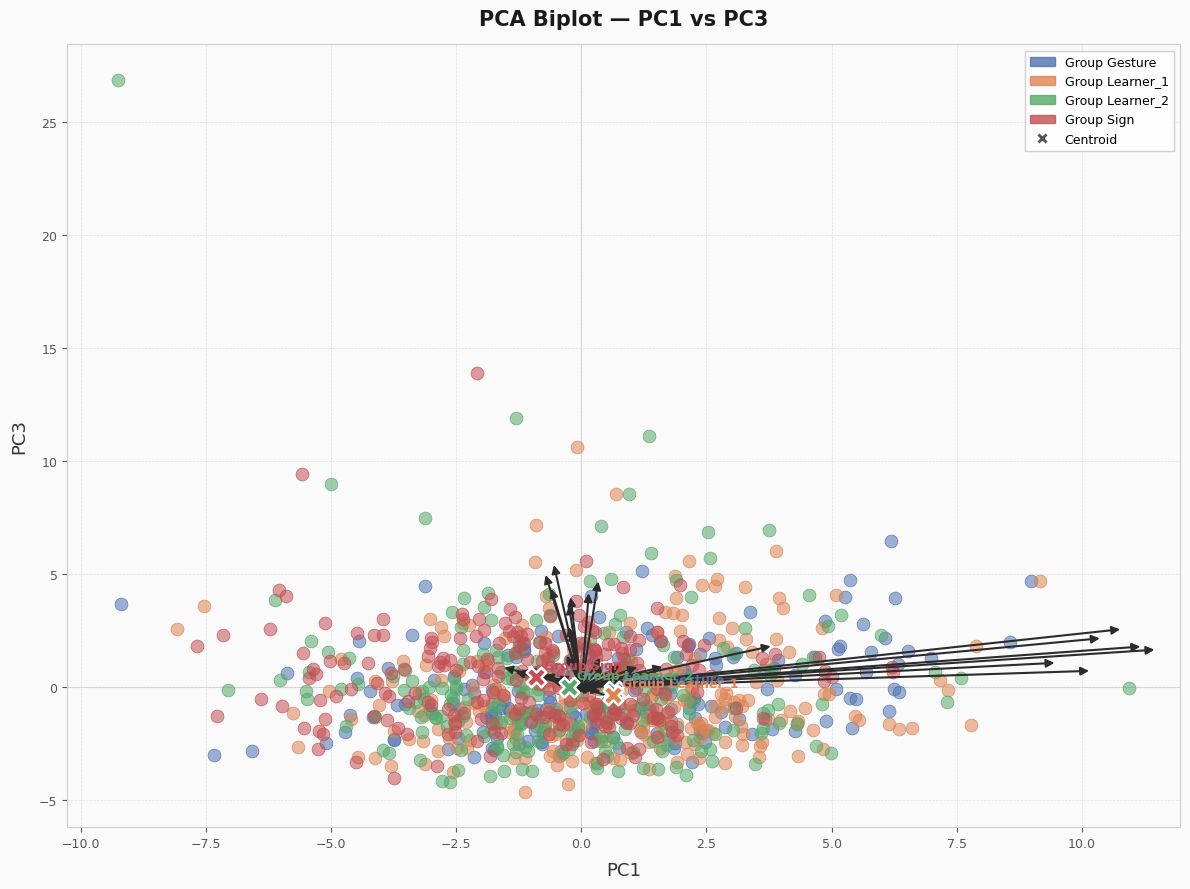

(<Figure size 1200x900 with 1 Axes>,
 <Axes: title={'center': 'PCA Biplot — PC1 vs PC3'}, xlabel='PC1', ylabel='PC3'>)

In [41]:
pcs_to_plot = [1, 3]  # PC1–PC2

sig_features_GS = (
    df_sig_vars_GS[
        (df_sig_vars_GS["sig_loading"]) &
        (df_sig_vars_GS["PC"].isin(pcs_to_plot))
    ]["feature"]
    .unique()
)

feature_names = df_clean.columns[:-1]
selected_vars = [feature_names.get_loc(f) for f in sig_features_GS if f in feature_names]

arrow_strength = (
    df_sig_vars_GS[df_sig_vars_GS["PC"].isin(pcs_to_plot)]
    .groupby("feature")["index_loading"]
    .mean()
    .to_dict()
)

interactive_PCA_biplot(
    score=x_new_GS, 
    coeff=loadings_GS, 
    labels=feature_names, 
    y=y, 
    selected_vars=selected_vars, 
    pc_x=pcs_to_plot[0], pc_y=pcs_to_plot[1],
    show_labels=False,
    arrow_strength=arrow_strength
)

# static plot
static_PCA_biplot(
    score=x_new_GS, 
    coeff=loadings_GS, 
    labels=feature_names, 
    y=y, 
    selected_vars=selected_vars, 
    pc_x=pcs_to_plot[0], pc_y=pcs_to_plot[1],
    show_labels=False,
    arrow_strength=arrow_strength,
    save_path=os.path.join(curfolder, "plots", "PCA_GS_all_PC1_3_biplot.png")
)


### Biplot PC1-PC4

Figure saved to: c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\plots\PCA_GS_all_PC1_4_biplot.png


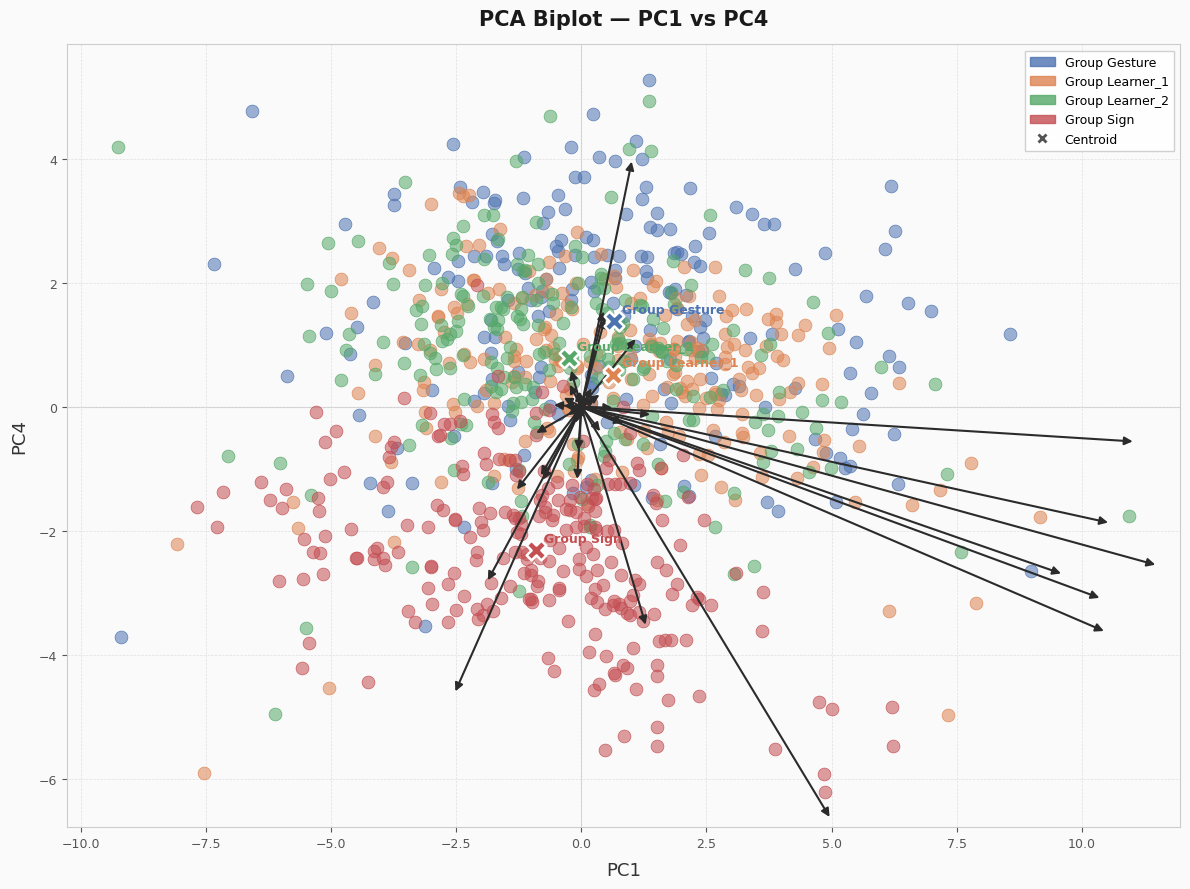

(<Figure size 1200x900 with 1 Axes>,
 <Axes: title={'center': 'PCA Biplot — PC1 vs PC4'}, xlabel='PC1', ylabel='PC4'>)

In [42]:
pcs_to_plot = [1, 4]  # PC1–PC2

sig_features_GS = (
    df_sig_vars_GS[
        (df_sig_vars_GS["sig_loading"]) &
        (df_sig_vars_GS["PC"].isin(pcs_to_plot))
    ]["feature"]
    .unique()
)

feature_names = df_clean.columns[:-1]
selected_vars = [feature_names.get_loc(f) for f in sig_features_GS if f in feature_names]

arrow_strength = (
    df_sig_vars_GS[df_sig_vars_GS["PC"].isin(pcs_to_plot)]
    .groupby("feature")["index_loading"]
    .mean()
    .to_dict()
)

interactive_PCA_biplot(
    score=x_new_GS, 
    coeff=loadings_GS, 
    labels=feature_names, 
    y=y, 
    selected_vars=selected_vars, 
    pc_x=pcs_to_plot[0], pc_y=pcs_to_plot[1],
    show_labels=False,
    arrow_strength=arrow_strength
)

# static plot
static_PCA_biplot(
    score=x_new_GS, 
    coeff=loadings_GS, 
    labels=feature_names, 
    y=y, 
    selected_vars=selected_vars, 
    pc_x=pcs_to_plot[0], pc_y=pcs_to_plot[1],
    show_labels=False,
    arrow_strength=arrow_strength,
    save_path=os.path.join(curfolder, "plots", "PCA_GS_all_PC1_4_biplot.png")
)

### Biplot PC1-PC5

Figure saved to: c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\plots\PCA_GS_all_PC1_5_biplot.png


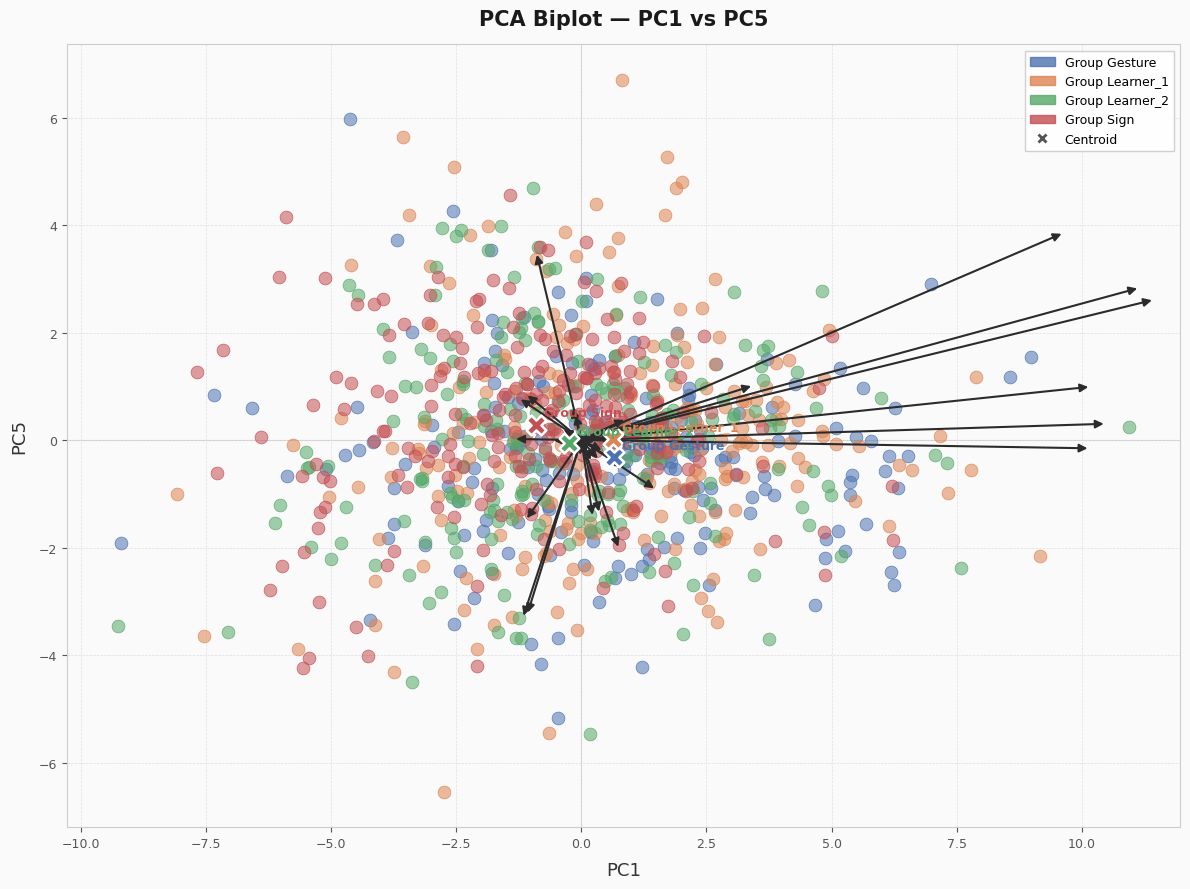

(<Figure size 1200x900 with 1 Axes>,
 <Axes: title={'center': 'PCA Biplot — PC1 vs PC5'}, xlabel='PC1', ylabel='PC5'>)

In [43]:
pcs_to_plot = [1, 5]  # PC1–PC2

sig_features_GS = (
    df_sig_vars_GS[
        (df_sig_vars_GS["sig_loading"]) &
        (df_sig_vars_GS["PC"].isin(pcs_to_plot))
    ]["feature"]
    .unique()
)

feature_names = df_clean.columns[:-1]
selected_vars = [feature_names.get_loc(f) for f in sig_features_GS if f in feature_names]

arrow_strength = (
    df_sig_vars_GS[df_sig_vars_GS["PC"].isin(pcs_to_plot)]
    .groupby("feature")["index_loading"]
    .mean()
    .to_dict()
)

interactive_PCA_biplot(
    score=x_new_GS, 
    coeff=loadings_GS, 
    labels=feature_names, 
    y=y, 
    selected_vars=selected_vars, 
    pc_x=pcs_to_plot[0], pc_y=pcs_to_plot[1],
    show_labels=False,
    arrow_strength=arrow_strength
)

# static plot
static_PCA_biplot(
    score=x_new_GS, 
    coeff=loadings_GS, 
    labels=feature_names, 
    y=y, 
    selected_vars=selected_vars, 
    pc_x=pcs_to_plot[0], pc_y=pcs_to_plot[1],
    show_labels=False,
    arrow_strength=arrow_strength,
    save_path=os.path.join(curfolder, "plots", "PCA_GS_all_PC1_5_biplot.png")
)


### Biplot PC4-PC5 

Figure saved to: c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\plots\PCA_GS_all_PC4_5_biplot.png


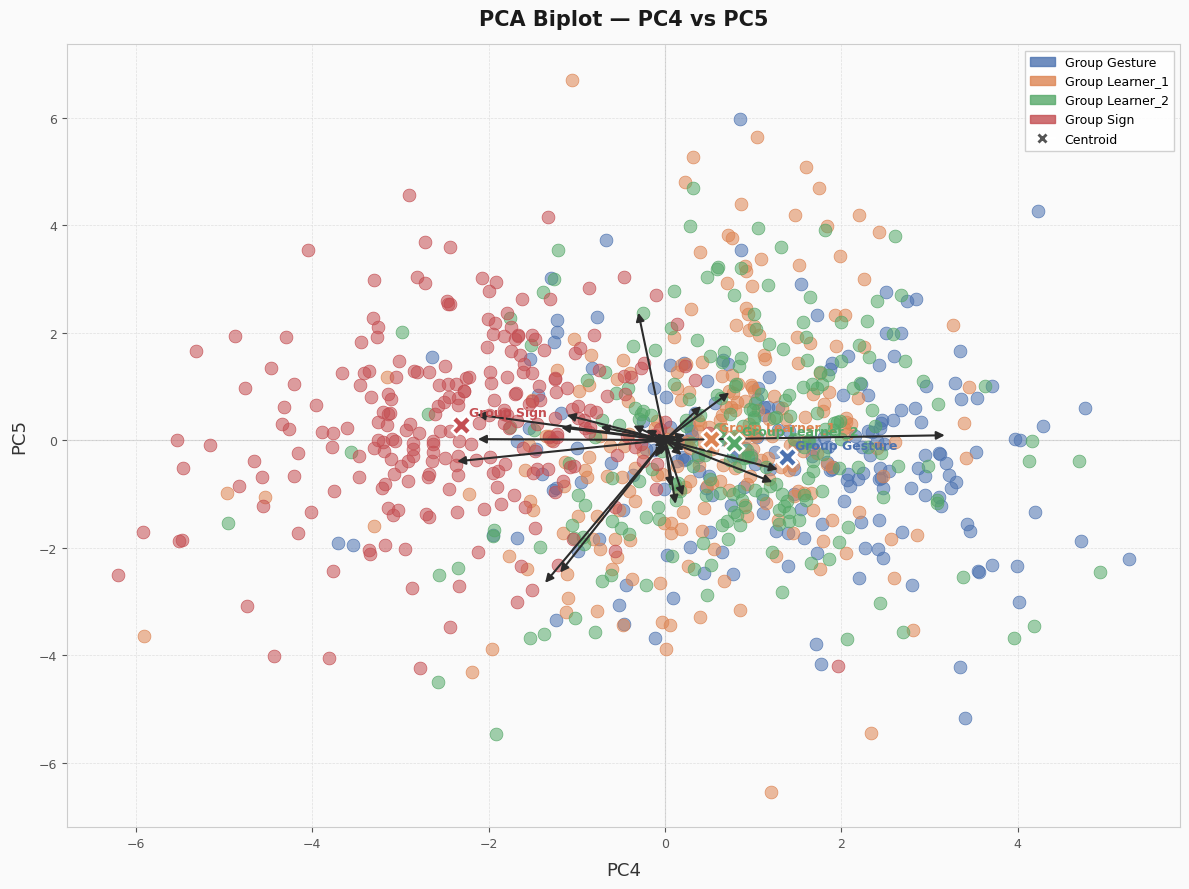

(<Figure size 1200x900 with 1 Axes>,
 <Axes: title={'center': 'PCA Biplot — PC4 vs PC5'}, xlabel='PC4', ylabel='PC5'>)

In [44]:
pcs_to_plot = [4, 5]  # PC1–PC2

sig_features_GS = (
    df_sig_vars_GS[
        (df_sig_vars_GS["sig_loading"]) &
        (df_sig_vars_GS["PC"].isin(pcs_to_plot))
    ]["feature"]
    .unique()
)

feature_names = df_clean.columns[:-1]
selected_vars = [feature_names.get_loc(f) for f in sig_features_GS if f in feature_names]

arrow_strength = (
    df_sig_vars_GS[df_sig_vars_GS["PC"].isin(pcs_to_plot)]
    .groupby("feature")["index_loading"]
    .mean()
    .to_dict()
)

interactive_PCA_biplot(
    score=x_new_GS, 
    coeff=loadings_GS, 
    labels=feature_names, 
    y=y, 
    selected_vars=selected_vars, 
    pc_x=pcs_to_plot[0], pc_y=pcs_to_plot[1],
    show_labels=False,
    arrow_strength=arrow_strength
)

# static plot
static_PCA_biplot(
    score=x_new_GS, 
    coeff=loadings_GS, 
    labels=feature_names, 
    y=y, 
    selected_vars=selected_vars, 
    pc_x=pcs_to_plot[0], pc_y=pcs_to_plot[1],
    show_labels=False,
    arrow_strength=arrow_strength,
    save_path=os.path.join(curfolder, "plots", "PCA_GS_all_PC4_5_biplot.png")
)


### 3D plot

In [260]:
def interactive_PCA_biplot_3D(score, coeff, labels=None, y=None, selected_vars=None,
                               arrow_strength=None, pc_x=1, pc_y=2, pc_z=3,
                               show_labels=True, concepts=None,
                               highlight_concepts=None, le=None):
    ix, iy, iz = pc_x - 1, pc_y - 1, pc_z - 1
    xs, ys, zs = score[:, ix], score[:, iy], score[:, iz]
    concepts = np.array(concepts) if concepts is not None else None

    if concepts is not None and len(concepts) != len(xs):
        print(f"Warning: concepts length ({len(concepts)}) doesn't match score rows ({len(xs)}). Ignoring concepts.")
        concepts = None

    def group_name(g):
        return le.inverse_transform([g])[0] if le is not None else f"Group {g}"

    # --- Discrete color mapping per group ---
    groups = np.unique(y)
    palette = [
        '#1f77b4', '#ff7f0e', '#2ca02c', '#d62728',
        '#9467bd', '#8c564b', '#e377c2', '#7f7f7f'
    ]
    color_map = {g: palette[i % len(palette)] for i, g in enumerate(groups)}

    traces = []

    # --- One scatter trace per group ---
    for g in groups:
        mask = y == g
        traces.append(go.Scatter3d(
            x=xs[mask], y=ys[mask], z=zs[mask],
            mode='markers',
            marker=dict(size=5, color=color_map[g], opacity=0.7),
            name=group_name(g),
            text=[group_name(g) + (f"<br>{concepts[i]}" if concepts is not None else "")
                  for i in np.where(mask)[0]],
            hoverinfo='text',
            showlegend=True
        ))

    # --- Highlighted concept overlays ---
    if concepts is not None and highlight_concepts is not None:
        for concept in highlight_concepts:
            mask = np.where(concepts == concept)[0]

            seen_groups = {}
            for idx in mask:
                group = y[idx]
                if group not in seen_groups:
                    seen_groups[group] = idx

            representative_indices = list(seen_groups.values())

            traces.append(go.Scatter3d(
                x=xs[representative_indices],
                y=ys[representative_indices],
                z=zs[representative_indices],
                mode='markers',
                marker=dict(size=10, color='red', symbol='diamond',
                            line=dict(color='black', width=1)),
                name=concept,
                text=[f"{concept} — {group_name(y[i])}" for i in representative_indices],
                hoverinfo='text',
                showlegend=True
            ))

    # --- Arrows ---
    vars_to_plot = selected_vars if selected_vars is not None else range(coeff.shape[0])
    arrow_scale = 10

    for i in vars_to_plot:
        var_name = f"Var{i+1}" if labels is None else labels[i]
        scale = arrow_scale * (arrow_strength.get(var_name, 1.0) if arrow_strength else 1.0)

        # Arrow line
        traces.append(go.Scatter3d(
            x=[0, coeff[i, ix] * scale],
            y=[0, coeff[i, iy] * scale],
            z=[0, coeff[i, iz] * scale],
            mode='lines+markers+text' if show_labels else 'lines+markers',
            line=dict(color='black', width=3),
            marker=dict(size=3, color='black'),
            text=[None, var_name] if show_labels else None,
            textposition='top center',
            hovertext=var_name,
            hoverinfo='text',
            showlegend=False
        ))

    layout = go.Layout(
        title=f"Interactive 3D PCA Biplot — PC{pc_x} vs PC{pc_y} vs PC{pc_z}",
        scene=dict(
            xaxis_title=f"PC{pc_x}",
            yaxis_title=f"PC{pc_y}",
            zaxis_title=f"PC{pc_z}",
        ),
        width=900, height=700,
    )

    go.Figure(data=traces, layout=layout).show()

In [262]:
pcs_to_plot = [2, 3, 4]

sig_features_GS = (
    df_sig_vars_GS[
        (df_sig_vars_GS["sig_loading"]) &
        (df_sig_vars_GS["PC"].isin(pcs_to_plot))
    ]["feature"]
    .unique()
)

# Map feature names to column indices
selected_vars = [feature_names.get_loc(f) for f in sig_features_GS if f in feature_names]


interactive_PCA_biplot_3D(
    score=x_new_GS,
    coeff=loadings_GS,
    labels=feature_names,
    y=y,
    selected_vars=selected_vars,
    pc_x=pcs_to_plot[0], pc_y=pcs_to_plot[1], pc_z=pcs_to_plot[2],
    show_labels=False,
    le=le,
    arrow_strength=arrow_strength
)

## Save features

In [92]:
def export_sigvars(df_sig, domain, out_name):
    out = df_sig.copy()
    out["PC"] = domain + "_PC" + out["PC"].astype(str)   # 3 -> "gross_PC3"
    out.to_csv(f"Datasets/{out_name}", index=False)

export_sigvars(df_sig_vars_GS,  "all",   "loadings_all.csv")     # <-- see caveat below
  

## Feature comparison

In [263]:
def plot_features_halfviolin_scatter(df, x, features, title):
    sns.set_theme(style="whitegrid", font_scale=1.2)
    palette = sns.color_palette("pastel", df[x].nunique())

    n = len(features)
    ncols = 2
    nrows = (n + 1) // 2
    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(16, 5 * nrows))
    axes = axes.flatten()

    for i, feature in enumerate(features):
        ax = axes[i]

        # Violin — hue replaces palette, density_norm replaces scale, bw_adjust replaces bw
        sns.violinplot(
            data=df, x=x, y=feature, ax=ax,
            hue=x, palette=palette, legend=False,
            inner=None, cut=0, linewidth=0.8, density_norm='width',
            bw_method='scott', bw_adjust=0.2, width=0.7
        )

        for violin in ax.collections:
            violin.set_alpha(0.3)

        sns.stripplot(
            data=df, x=x, y=feature, ax=ax,
            jitter=0.2, dodge=True, color='black', alpha=0.6, size=3
        )

        # pointplot — errorbar replaces ci, linestyle replaces join, err_kws replaces errwidth
        sns.pointplot(
            data=df, x=x, y=feature, ax=ax,
            color='gray', errorbar='sd', linestyle='none', markers='D',
            markersize=5, err_kws={'linewidth': 1}, capsize=0.1
        )

        ax.set_title(feature, fontsize=14, weight='semibold', pad=10)
        ax.set_xlabel('')
        ax.set_ylabel('Value', labelpad=10)
        ax.grid(True, linestyle='--', alpha=0.25)
        # fix the FixedLocator warning
        ax.set_xticks(ax.get_xticks())
        ax.set_xticklabels(ax.get_xticklabels(), rotation=15)

    # hide unused axes if features is not a multiple of 2
    for j in range(n, len(axes)):
        axes[j].set_visible(False)

    plt.suptitle(title, fontsize=20, weight='bold')
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

In [267]:
# Get the first significant variable per each significant PC
first_sig_vars_GS = df_sig_vars_GS[df_sig_vars_GS["sig_loading"]].groupby("PC").apply(lambda x: x.iloc[0])["feature"].to_dict()
print(first_sig_vars_GS)

{1: 'gross__magnitude__arm_speed_Gmean', 2: 'gross__magnitude__arm_speed_Gmean', 3: 'gross__magnitude__arm_speed_Gmean', 4: 'gross__magnitude__arm_speed_Gmean', 5: 'gross__rhythm__arm_acc_mod_depth', 6: 'gross__rhythm__arm_speed_peak_rate', 7: 'gross__smoothness__arm_sparc', 8: 'gross__smoothness__arm_sparc', 9: 'gross__variability__arm_speed_peak_std', 10: 'gross__rhythm__band1_dom_freq_totalarm', 11: 'gross__variability__arm_speed_peak_std', 12: 'gross__magnitude__bbmv_arms_total', 13: 'gross__coordination__arm_coupling', 14: 'gross__proxdist__proximalization_index', 15: 'gross__smoothness__arm_sparc', 16: 'fine__proxdist__distal_proximal_ratio', 17: 'gross__proxdist__directness_arms', 18: 'gross__proxdist__directness_arms', 19: 'fine__smoothness__flexion_jerk', 22: 'gross__rhythm__band3_dom_freq_totalarm', 23: 'fine__coordination__corr_index_middle', 24: 'fine__variability__flexion_entropy', 26: 'fine__coordination__corr_middle_ring'}


C:\Users\kadava\AppData\Local\Temp\ipykernel_22160\2082513646.py:2: DeprecationWarning:

DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.



Features to plot: ['gross__magnitude__arm_speed_Gmean', 'gross__magnitude__arm_speed_Gmean', 'gross__magnitude__arm_speed_Gmean', 'gross__magnitude__arm_speed_Gmean', 'gross__rhythm__arm_acc_mod_depth', 'gross__rhythm__arm_speed_peak_rate', 'gross__smoothness__arm_sparc', 'gross__smoothness__arm_sparc', 'gross__variability__arm_speed_peak_std', 'gross__rhythm__band1_dom_freq_totalarm', 'gross__variability__arm_speed_peak_std', 'gross__magnitude__bbmv_arms_total', 'gross__coordination__arm_coupling', 'gross__proxdist__proximalization_index', 'gross__smoothness__arm_sparc', 'fine__proxdist__distal_proximal_ratio', 'gross__proxdist__directness_arms', 'gross__proxdist__directness_arms', 'fine__smoothness__flexion_jerk', 'gross__rhythm__band3_dom_freq_totalarm', 'fine__coordination__corr_index_middle', 'fine__variability__flexion_entropy', 'fine__coordination__corr_middle_ring']


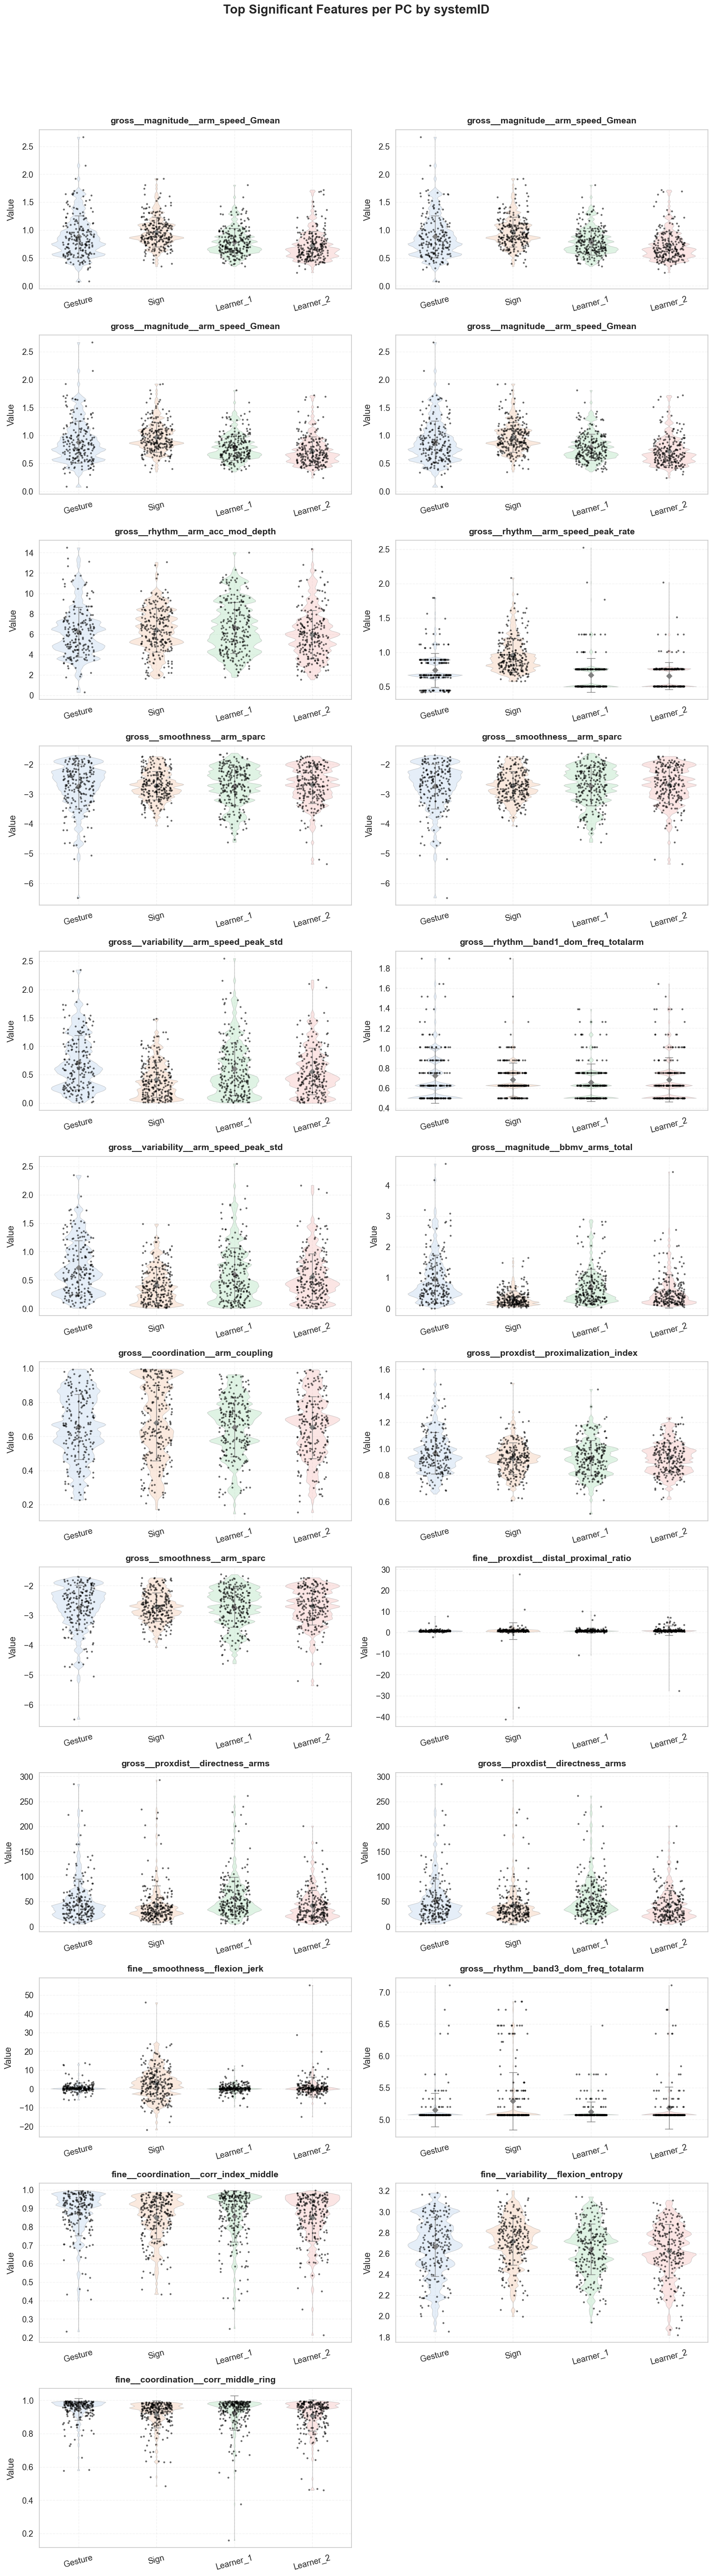

In [265]:
# make them into list
features_to_plot = list(first_sig_vars_GS.values())
print("Features to plot:", features_to_plot)

plot_features_halfviolin_scatter(df_clean, 'groupID', features_to_plot, title="Top Significant Features per PC by systemID")

# PCA: All groups (gross only)

In [93]:
# read it
df_clean = pd.read_csv(os.path.join(curfolder, 'Datasets', 'sampled_merged_sapiens_cleanforPCA_noprune.csv'))

In [94]:
# get rid of all columns with fine_ in the name
cols_to_drop = [col for col in df_clean.columns if col.startswith('fine_')]

df_clean = df_clean.drop(columns=cols_to_drop)

In [95]:
feature_names = df_clean.columns[:-1].to_list()

# Prepare data
X = df_clean.iloc[:, :-1].values  # All columns except the last as features
y = df_clean.iloc[:, -1].values   # Last column as target variable

# Convert categorical target to numeric if necessary
if y.dtype == 'object' or y.dtype.name == 'category':
    le = LabelEncoder()
    y = le.fit_transform(y)  # Converts categorical labels into numeric labels

# Scale the data
scaler_GSG = StandardScaler()
Xz_GSG = scaler_GSG.fit_transform(X)    

# PCA transformation
pca_GSG = PCA()
x_new_GSG = pca_GSG.fit_transform(Xz_GSG)

# Get the PCA loadings (components_ is shape: [n_components, n_features])
loadings_GSG = pca_GSG.components_.T

# Number of top variables to show per PC
top_n = 10

# Get top variables per PC by absolute contribution
top_vars = set()
for i in range(2):  # for PC1, PC2, PC3
    component = loadings_GSG[i]
    top_indices = np.argsort(np.abs(component))[-top_n:]
    top_vars.update(top_indices)

# Convert to sorted list for consistency
selected_vars = sorted(top_vars)

# Plot
interactive_PCA_biplot(score=x_new_GSG, 
                       coeff=loadings_GSG, 
                       labels=feature_names, 
                       y=y, 
                       selected_vars=selected_vars, 
                       pc_x=1, pc_y=2,
                       show_labels=False,
                        arrow_strength=arrow_strength                    )

In [52]:
# PC2-3
interactive_PCA_biplot(score=x_new_GSG,
                          coeff=loadings_GSG, 
                          labels=feature_names, 
                          y=y, 
                          selected_vars=selected_vars, 
                          pc_x=2, pc_y=3,
                          show_labels=False,
                            arrow_strength=arrow_strength                      )

Figure saved to: c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\plots\PCA_GSG_PC1_2_biplot.png


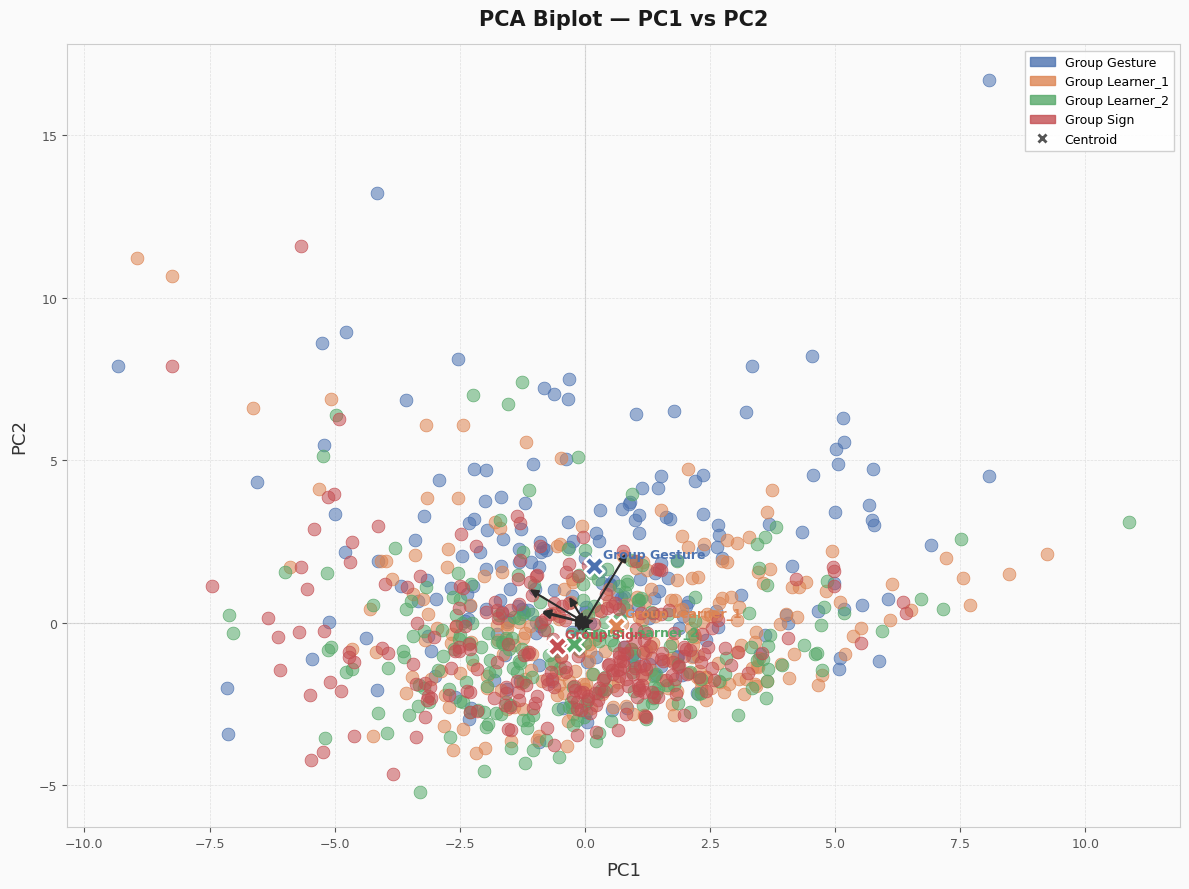

Figure saved to: c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\plots\PCA_GSG_PC2_3_biplot.png


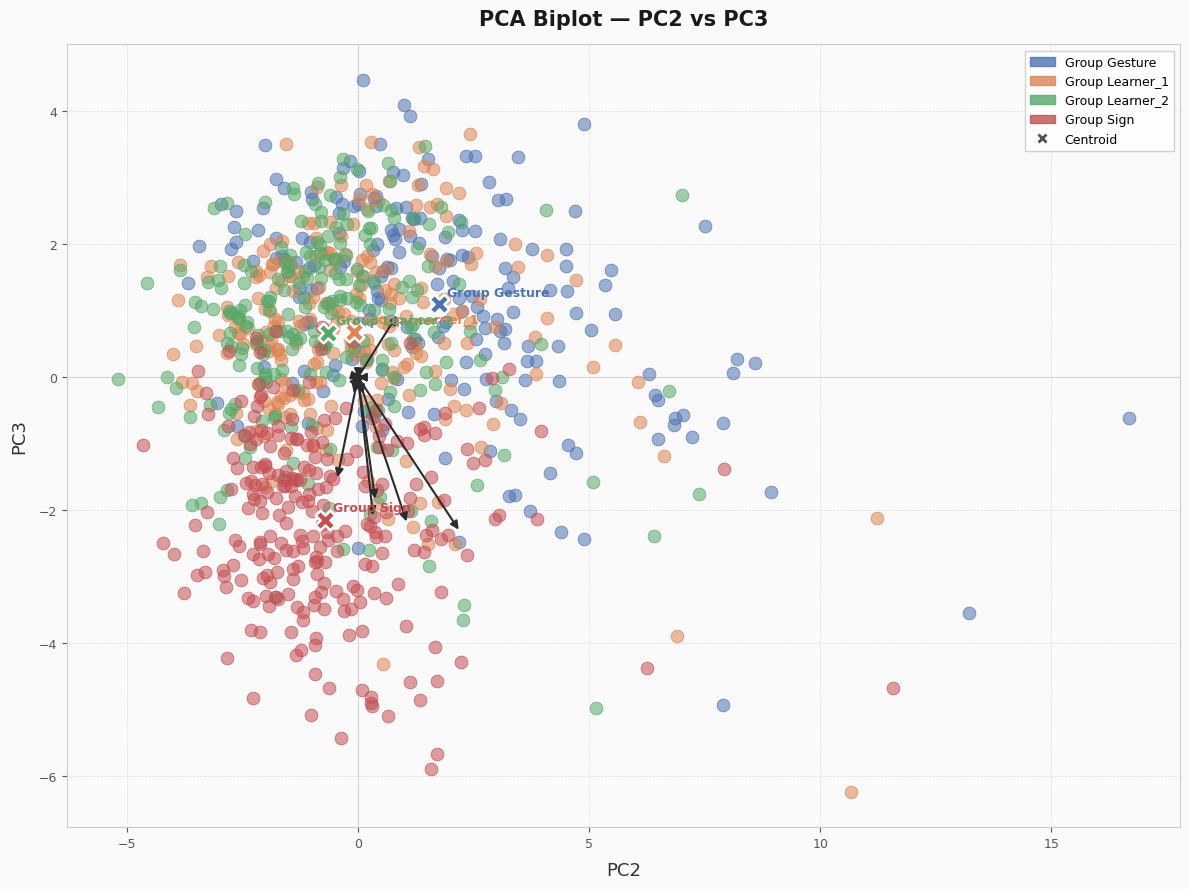

Figure saved to: c:\Users\kadava\Documents\Github\GtST_FLESH_KinTrajectory\plots\PCA_GSG_PC3_4_biplot.png


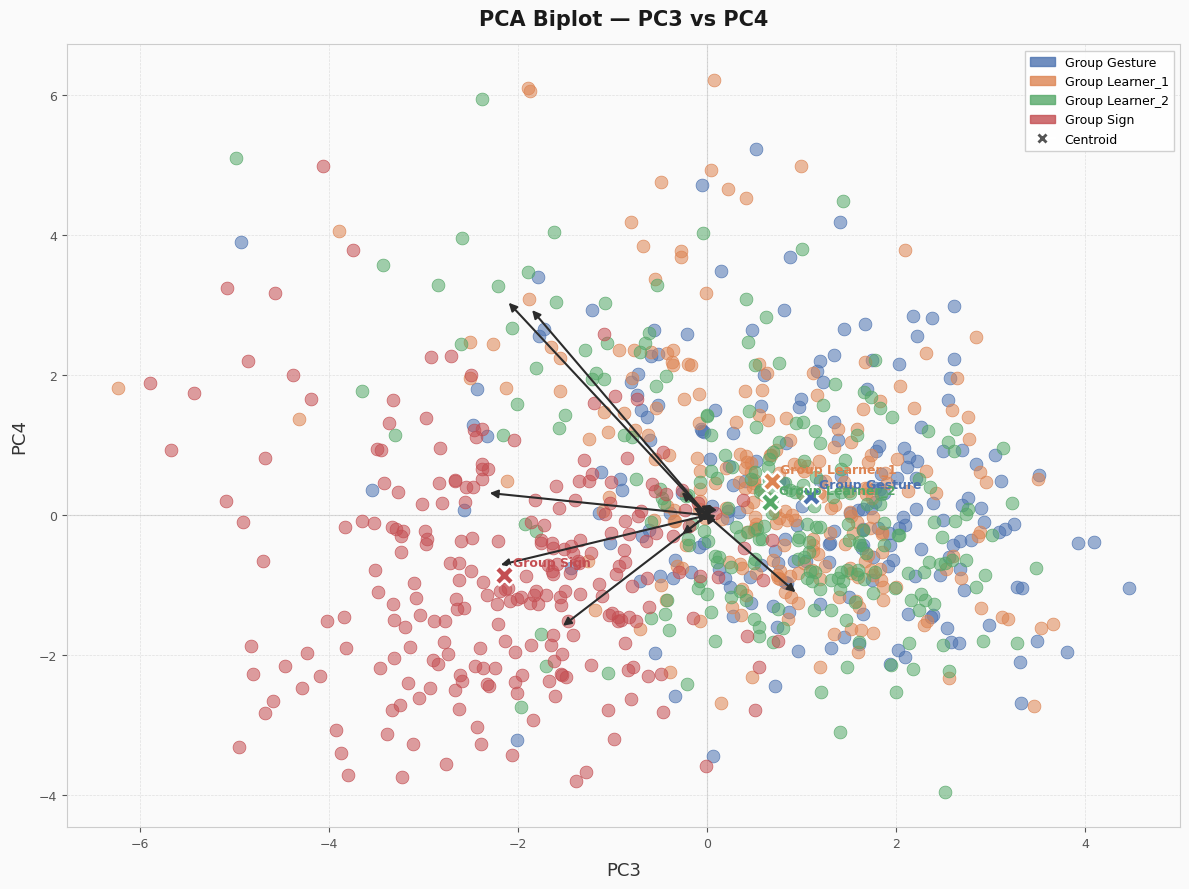

(<Figure size 1200x900 with 1 Axes>,
 <Axes: title={'center': 'PCA Biplot — PC3 vs PC4'}, xlabel='PC3', ylabel='PC4'>)

In [53]:
# static 1-2
static_PCA_biplot(score=x_new_GSG, 
                       coeff=loadings_GSG, 
                       labels=feature_names, 
                       y=y, 
                       selected_vars=selected_vars, 
                       pc_x=1, pc_y=2,
                       show_labels=False,
                        arrow_strength=arrow_strength,
                       save_path=os.path.join(curfolder, "plots", "PCA_GSG_PC1_2_biplot.png")
                    )

# static 2-3
static_PCA_biplot(score=x_new_GSG,
                       coeff=loadings_GSG, 
                       labels=feature_names, 
                       y=y, 
                       selected_vars=selected_vars, 
                       pc_x=2, pc_y=3,
                       show_labels=False,
                        arrow_strength=arrow_strength,
                       save_path=os.path.join(curfolder, "plots", "PCA_GSG_PC2_3_biplot.png")
                    )

# 3-4
static_PCA_biplot(score=x_new_GSG,
                       coeff=loadings_GSG, 
                       labels=feature_names, 
                       y=y, 
                       selected_vars=selected_vars, 
                       pc_x=3, pc_y=4,
                       show_labels=False,
                        arrow_strength=arrow_strength,
                       save_path=os.path.join(curfolder, "plots", "PCA_GSG_PC3_4_biplot.png")
                    )

## Bootstraping and significance

In [96]:
bootstrap_results_GSG = bootstrap_pca(Xz_GSG)
permutation_results_GSG = permutation_pca(Xz_GSG)

# determine significant PCs
var_explained_GSG = pca_GSG.explained_variance_ratio_
null_var_thresh_GSG = permutation_results_GSG["null_eig_thresh"] / np.sum(pca_GSG.explained_variance_)  # convert eig to variance ratio
sig_pc_null_GSG = var_explained_GSG > null_var_thresh_GSG

# apply 5-10 % cut-off
sig_pc_effect_GSG = var_explained_GSG > 0.05  # 5% cut-off
sig_pc_GSG = sig_pc_null_GSG & sig_pc_effect_GSG

print("Significant PCs:")
for i, sig in enumerate(sig_pc_GSG, start=1):
    print(f"PC{i}: significant = {sig}, var explained = {var_explained_GSG[i-1]:.3f}")



Significant PCs:
PC1: significant = True, var explained = 0.225
PC2: significant = True, var explained = 0.175
PC3: significant = True, var explained = 0.107
PC4: significant = True, var explained = 0.077
PC5: significant = True, var explained = 0.051
PC6: significant = False, var explained = 0.042
PC7: significant = False, var explained = 0.041
PC8: significant = False, var explained = 0.037
PC9: significant = False, var explained = 0.033
PC10: significant = False, var explained = 0.027
PC11: significant = False, var explained = 0.026
PC12: significant = False, var explained = 0.023
PC13: significant = False, var explained = 0.021
PC14: significant = False, var explained = 0.018
PC15: significant = False, var explained = 0.018
PC16: significant = False, var explained = 0.017
PC17: significant = False, var explained = 0.013
PC18: significant = False, var explained = 0.011
PC19: significant = False, var explained = 0.008
PC20: significant = False, var explained = 0.007
PC21: significant

## Identify sig variables

In [97]:
df_sig_vars_GSG = identify_sigvar(pca_GSG, bootstrap_results_GSG, permutation_results_GSG, df_clean)
df_sig_vars_GSG[df_sig_vars_GSG["sig_loading"]].sort_values(["PC", "index_loading"], ascending=[True, False])

,PC,feature,loading,index_loading,low_confint,high_confint,low_null,high_null,sig_loading
9,1,gross__magnitude__arm_acc_peak_mean,0.333599,6.895359,4.968361,8.400591,0.000383,0.215224,True
6,1,gross__rhythm__arm_speed_mod_depth,0.328279,6.677168,5.263487,7.886836,0.000222,0.194735,True
8,1,gross__variability__arm_acc_Gstd,0.325814,6.577273,4.465093,8.198529,0.000202,0.184885,True
13,1,gross__rhythm__arm_acc_mod_depth,0.318785,6.296566,4.794404,7.393579,0.000367,0.178013,True
1,1,gross__variability__arm_speed_Gstd,0.317387,6.241452,3.900336,8.300450,0.000197,0.187982,True
...,...,...,...,...,...,...,...,...,...
349,10,gross__proxdist__proximalization_index,0.689926,0.441764,0.011015,0.538460,0.000136,0.135240,True
347,10,gross__coordination__arm_coupling,-0.431420,0.172737,0.004066,0.298071,0.000219,0.141980,True
367,11,gross__smoothness__arm_sparc,0.525656,0.221160,0.002094,0.222177,0.000205,0.132957,True
416,12,gross__proxdist__directness_arms,0.842729,0.471630,0.001441,0.459573,0.000148,0.125566,True


In [63]:
import os
sig_idx = np.where(sig_pc_GSG)[0]                       # significant PCs (null AND >=5%)
pc_cols = [f"PC{i+1}" for i in sig_idx]
scores  = pd.DataFrame(x_new_GSG[:, sig_idx], columns=pc_cols)

# metadata MUST be the same rows, same order, that went into pca_GS.fit_transform(Xz_GS).
# NOTE: clean_df() drops the participant column ('group'), so pull metadata from sampled_df
# (post-LP-removal, post-dropna) which still has group / groupID / concept.
meta = (sampled_df[['group', 'groupID', 'concept']]
        .reset_index(drop=True)
        .rename(columns={'group': 'participant'}))
assert len(meta) == len(scores), "row mismatch — metadata not aligned with PCA scores!"
# optional strong check: groupID order matches the PCA target
# assert (meta['groupID'].values == df_clean.iloc[:, -1].values).all()

out = pd.concat([scores, meta], axis=1)
for row in out.itertuples():
    if row.participant.startswith('IP'):
        out.loc[row.Index, 'participant'] = row.participant.split('_')[0]

out.to_csv(os.path.join(curfolder, 'Datasets', 'pca_scores_gross.csv'), index=False)

In [98]:
export_sigvars(df_sig_vars_GSG, "gross", "loadings_gross.csv")

# PCA: All groups (fine only)

In [99]:
# read it
df_clean = pd.read_csv(os.path.join(curfolder, 'Datasets', 'sampled_merged_sapiens_cleanforPCA_noprune.csv'))

In [100]:
# get rid of all columns with fine_ in the name
cols_to_drop = [col for col in df_clean.columns if col.startswith('gross_')]

df_clean = df_clean.drop(columns=cols_to_drop)

In [101]:
feature_names = df_clean.columns[:-1].to_list()

# Prepare data
X = df_clean.iloc[:, :-1].values  # All columns except the last as features
y = df_clean.iloc[:, -1].values   # Last column as target variable

# Convert categorical target to numeric if necessary
if y.dtype == 'object' or y.dtype.name == 'category':
    le = LabelEncoder()
    y = le.fit_transform(y)  # Converts categorical labels into numeric labels

# Scale the data
scaler_GSF = StandardScaler()
Xz_GSF = scaler_GSF.fit_transform(X)    

# PCA transformation
pca_GSF = PCA()
x_new_GSF = pca_GSF.fit_transform(Xz_GSF)

# Get the PCA loadings (components_ is shape: [n_components, n_features])
loadings_GSF = pca_GSF.components_.T

# Number of top variables to show per PC
top_n = 10

# Get top variables per PC by absolute contribution
top_vars = set()
for i in range(2):  # for PC1, PC2, PC3
    component = loadings_GSF[i]
    top_indices = np.argsort(np.abs(component))[-top_n:]
    top_vars.update(top_indices)

# Convert to sorted list for consistency
selected_vars = sorted(top_vars)

# Plot
interactive_PCA_biplot(score=x_new_GSF, 
                       coeff=loadings_GSF, 
                       labels=feature_names, 
                       y=y, 
                       selected_vars=selected_vars, 
                       pc_x=1, pc_y=2,
                       show_labels=False,
                        arrow_strength=arrow_strength                    )

## Bootstraping and significance

In [102]:
bootstrap_results_GSF = bootstrap_pca(Xz_GSF)
permutation_results_GSF = permutation_pca(Xz_GSF)

# determine significant PCs
var_explained_GSF = pca_GSF.explained_variance_ratio_
null_var_thresh_GSF = permutation_results_GSF["null_eig_thresh"] / np.sum(pca_GSF.explained_variance_)  # convert eig to variance ratio
sig_pc_null_GSF = var_explained_GSF > null_var_thresh_GSF

# apply 5-10 % cut-off
sig_pc_effect_GSF = var_explained_GSF > 0.05  # 5% cut-off
sig_pc_GSF = sig_pc_null_GSF & sig_pc_effect_GSF

print("Significant PCs:")
for i, sig in enumerate(sig_pc_GSF, start=1):
    print(f"PC{i}: significant = {sig}, var explained = {var_explained_GSF[i-1]:.3f}")



Significant PCs:
PC1: significant = True, var explained = 0.298
PC2: significant = True, var explained = 0.153
PC3: significant = True, var explained = 0.101
PC4: significant = True, var explained = 0.089
PC5: significant = True, var explained = 0.058
PC6: significant = False, var explained = 0.052
PC7: significant = False, var explained = 0.048
PC8: significant = False, var explained = 0.043
PC9: significant = False, var explained = 0.035
PC10: significant = False, var explained = 0.028
PC11: significant = False, var explained = 0.024
PC12: significant = False, var explained = 0.021
PC13: significant = False, var explained = 0.017
PC14: significant = False, var explained = 0.014
PC15: significant = False, var explained = 0.008
PC16: significant = False, var explained = 0.007
PC17: significant = False, var explained = 0.002
PC18: significant = False, var explained = 0.001
PC19: significant = False, var explained = 0.000
PC20: significant = False, var explained = 0.000


## Identify sig variables

In [103]:
df_sig_vars_GSF = identify_sigvar(pca_GSF, bootstrap_results_GSF, permutation_results_GSF, df_clean)
df_sig_vars_GSF[df_sig_vars_GSF["sig_loading"]].sort_values(["PC", "index_loading"], ascending=[True, False])

,PC,feature,loading,index_loading,low_confint,high_confint,low_null,high_null,sig_loading
0,1,fine__handshape__fingertip_spread_mean,0.345746,4.248662,2.772711,6.381518,0.000466,0.265067,True
2,1,fine__handshape__thumb_index_mean,0.339532,4.097304,2.199733,7.338495,0.000384,0.287760,True
1,1,fine__variability__fingertip_spread_std,0.329082,3.848987,1.901707,7.437163,0.000479,0.318163,True
10,1,fine__variability__handshape_variability,0.320905,3.660075,2.216387,5.819030,0.000649,0.266144,True
3,1,fine__variability__thumb_index_std,0.314107,3.506645,1.900448,5.887730,0.000371,0.274098,True
4,1,fine__handshape__mcp_tip_mean,0.311925,3.458111,1.646512,6.843880,0.000341,0.281458,True
5,1,fine__variability__mcp_tip_std,0.280536,2.797153,0.967573,6.571803,0.000427,0.276337,True
11,1,fine__magnitude__flexion_speed_mean,0.250699,2.233794,0.878064,4.602442,0.000552,0.286921,True
12,1,fine__variability__flexion_speed_std,0.242409,2.088501,0.790850,4.604899,0.000350,0.296745,True
6,1,fine__handshape__thumb_opposition_mean,0.223968,1.782834,1.297237,2.315489,0.000387,0.272680,True


In [ ]:
import os
sig_idx = np.where(sig_pc_GSF)[0]                       # significant PCs (null AND >=5%)
pc_cols = [f"PC{i+1}" for i in sig_idx]
scores  = pd.DataFrame(x_new_GSF[:, sig_idx], columns=pc_cols)

# metadata MUST be the same rows, same order, that went into pca_GS.fit_transform(Xz_GS).
# NOTE: clean_df() drops the participant column ('group'), so pull metadata from sampled_df
# (post-LP-removal, post-dropna) which still has group / groupID / concept.
meta = (sampled_df[['group', 'groupID', 'concept']]
        .reset_index(drop=True)
        .rename(columns={'group': 'participant'}))
assert len(meta) == len(scores), "row mismatch — metadata not aligned with PCA scores!"
# optional strong check: groupID order matches the PCA target
# assert (meta['groupID'].values == df_clean.iloc[:, -1].values).all()

out = pd.concat([scores, meta], axis=1)
for row in out.itertuples():
    if row.participant.startswith('IP'):
        out.loc[row.Index, 'participant'] = row.participant.split('_')[0]

out.to_csv(os.path.join(curfolder, 'Datasets', 'pca_scores_fine.csv'), index=False)

In [104]:
export_sigvars(df_sig_vars_GSF,"fine",  "loadings_fine.csv")